# URBAN ENVIRONMENTAL ANOMALY DETECTION USING UNSUPERVISED MACHINE LEARNING

## PROJECT OVERVIEW

This project aims to detect unusual environmental patterns in an urban area using unsupervised machine learning.

The project uses the Beijing Multi-Site Air Quality Dataset, which contains hourly air-quality and meteorological data collected from 12 monitoring stations in Beijing from March 2013 to February 2017.

The data includes pollutants such as PM2.5, PM10, SO₂, NO₂, CO, and O₃, along with weather parameters such as temperature, pressure, rainfall, dew point, wind direction, and wind speed.

The hourly data will be cleaned and transformed into daily environmental profiles. K-Means Clustering will be used to identify common environmental patterns, while Isolation Forest will be used to detect days that behave unusually compared with normal historical patterns.

## PROJECT OBJECTIVE

To identify unusual environmental days using unsupervised machine learning and determine the key pollution and weather factors responsible for these anomalies. The project will also analyze when these anomalies occur and whether they are localized to specific 
monitoring stations or observed across the city.

What? → Anomalous environmental conditions

How? → Unsupervised ML

Why? → Identify contributing pollution/weather factors

When? → Temporal and seasonal patterns

Where? → Across 12 monitoring stations / spatial pattern

## DATASET

- Dataset: Beijing Multi-Site Air Quality Dataset
- Time Period: March 2013 – February 2017
- Monitoring Stations: 12
- Data Frequency: Hourly
- Total Records: 420,768

# STEP 1 — DATASET LOADING AND STRUCTURE INSPECTION

In this step, we will load the dataset, inspect its structure, understand the available features, check data types, identify missing values, examine duplicate records, and understand the time period covered by the data.

No data cleaning or machine learning will be performed in this step.

In [1]:
import pandas as pd

df = pd.read_csv(
    "../dataset/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

## 1.1 CHECK DATASET DIMENSIONS

First, we will check the number of rows and columns in the dataset.

This helps us verify that the dataset has been loaded correctly and understand its initial size.

In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 35064
Number of columns: 18


## 1.2 INSPECT COLUMN NAMES

Next, we will examine all the columns available in the dataset to understand what information is recorded for each observation.

In [3]:
print("Columns in the dataset:")
df.columns.tolist()

Columns in the dataset:


['No',
 'year',
 'month',
 'day',
 'hour',
 'PM2.5',
 'PM10',
 'SO2',
 'NO2',
 'CO',
 'O3',
 'TEMP',
 'PRES',
 'DEWP',
 'RAIN',
 'wd',
 'WSPM',
 'station']

## UNDERSTAND THE COLUMNS
## IDENTIFICATION / TIME
| Column  | Meaning                 |
|---------|-------------------------|
| `PM2.5` | Fine particulate matter |
| `PM10`  | Particulate matter      |
| `SO2`   | Sulfur dioxide          |
| `NO20`  | Nitrogen dioxide        |
| `CO`    | Carbon monoxide         |
| `O3`    | Ozone                   |

## AIR POLLUTANTS
| Column  | Meaning                 |
|---------|-------------------------|
| `PM2.5` | Fine particulate matter |
| `PM10`  | Particulate matter      |
| `SO2`   | Sulfur dioxide          |
| `NO2`   | Nitrogen dioxide        |
| `CO`    | Carbon monoxide         |
| `O3`    | Ozone                   | 

## METEOROLOGICAL VARIABLES
| Column | Meaning               |
|--------|-----------------------|
| `TEMP` | Temperature           |
| `PRES` | Atmospheric pressure  |
| `DEWP` | Dew point temperature |
| `RAIN` | Rainfall              |
| `wd`   | Wind direction        |
| `WSPM` | Wind speed            |


## 1.3 VIEW SAMPLE RECORDS

We will now display the first few records to understand how the data is structured and what an individual hourly observation looks like.

In [4]:
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


## 1.4 CHECK DATA TYPES

In this step, we will check the data type of each column.

This is important because machine learning algorithms require numerical features, while some columns such as wind direction and station name contain categorical information.

In [5]:
df.dtypes

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object

## 1.5 CHECK MISSING VALUES

Environmental datasets may contain missing observations.

We will identify the number of missing values in each column. We will not handle or replace the missing values yet; that will be done during the data-cleaning phase.

In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
No            0
year          0
month         0
day           0
hour          0
PM2.5       925
PM10        718
SO2         935
NO2        1023
CO         1776
O3         1719
TEMP         20
PRES         20
DEWP         20
RAIN         20
wd           81
WSPM         14
station       0
dtype: int64


## 1.6 CHECK DUPLICATE RECORDS

We will check whether the dataset contains completely duplicated rows.

At this stage, we will only identify duplicates and will not remove them.

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 1.7 CHECK TIME PERIOD

The dataset contains separate columns for year, month, day, and hour.

We will first check the range of years covered by this station's observations.

In [8]:
print("Starting year:", df["year"].min())
print("Ending year:", df["year"].max())

Starting year: 2013
Ending year: 2017


## 1.8 CREATE DATETIME COLUMN

The dataset stores year, month, day, and hour in separate columns.

We will combine these columns into a single datetime column. This will make it easier to perform time-based analysis and later convert the hourly observations into daily environmental profiles.

In [9]:
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df[["datetime", "year", "month", "day", "hour"]].head()

,datetime,year,month,day,hour
0,2013-03-01 00:00:00,2013,3,1,0
1,2013-03-01 01:00:00,2013,3,1,1
2,2013-03-01 02:00:00,2013,3,1,2
3,2013-03-01 03:00:00,2013,3,1,3
4,2013-03-01 04:00:00,2013,3,1,4


## 1.9 VERIFY DATETIME RANGE

Finally, we will verify the earliest and latest timestamps after creating the datetime column.

In [10]:
print("First observation:", df["datetime"].min())
print("Last observation:", df["datetime"].max())

First observation: 2013-03-01 00:00:00
Last observation: 2017-02-28 23:00:00


# STEP 2 — COMBINING ALL MONITORING STATIONS

The dataset contains hourly environmental observations from 12 monitoring stations in Beijing.

In this step, we will load the CSV file of each station and combine them into a single master dataset.

This will allow us to perform data cleaning, feature engineering, and machine learning on all monitoring stations together.

## 2.1 DEFINE MONITORING STATIONS

The dataset contains 12 monitoring stations. We will store their names in a list so that the files can be loaded systematically instead of writing separate code for every station.

In [11]:
stations = [
    "Aotizhongxin",
    "Changping",
    "Dingling",
    "Dongsi",
    "Guanyuan",
    "Gucheng",
    "Huairou",
    "Nongzhanguan",
    "Shunyi",
    "Tiantan",
    "Wanliu",
    "Wanshouxigong"
]

print("Number of monitoring stations:", len(stations))
print("Stations:", stations)

Number of monitoring stations: 12
Stations: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


## 2.2 LOAD ALL 12 STATION DATASETS

The Beijing Multi-Site Air Quality Dataset contains 12 monitoring station files.

We will load each CSV file separately into its own DataFrame so that the data from every monitoring station can be inspected individually before combining them into a master dataset.

In [12]:
# Load all 12 monitoring station datasets

aotizhongxin_df = pd.read_csv(
    "../dataset/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

changping_df = pd.read_csv(
    "../dataset/PRSA_Data_Changping_20130301-20170228.csv"
)

dingling_df = pd.read_csv(
    "../dataset/PRSA_Data_Dingling_20130301-20170228.csv"
)

dongsi_df = pd.read_csv(
    "../dataset/PRSA_Data_Dongsi_20130301-20170228.csv"
)

guanyuan_df = pd.read_csv(
    "../dataset/PRSA_Data_Guanyuan_20130301-20170228.csv"
)

gucheng_df = pd.read_csv(
    "../dataset/PRSA_Data_Gucheng_20130301-20170228.csv"
)

huairou_df = pd.read_csv(
    "../dataset/PRSA_Data_Huairou_20130301-20170228.csv"
)

nongzhanguan_df = pd.read_csv(
    "../dataset/PRSA_Data_Nongzhanguan_20130301-20170228.csv"
)

shunyi_df = pd.read_csv(
    "../dataset/PRSA_Data_Shunyi_20130301-20170228.csv"
)

tiantan_df = pd.read_csv(
    "../dataset/PRSA_Data_Tiantan_20130301-20170228.csv"
)

wanliu_df = pd.read_csv(
    "../dataset/PRSA_Data_Wanliu_20130301-20170228.csv"
)

wanshouxigong_df = pd.read_csv(
    "../dataset/PRSA_Data_Wanshouxigong_20130301-20170228.csv"
)

print("All 12 station datasets loaded successfully.")

All 12 station datasets loaded successfully.


## 2.3 VERIFY INDIVIDUAL DATASET DIMENSIONS

Before combining the datasets, we will verify the number of rows and columns in each station dataset.

In [13]:
print("Aotizhongxin:", aotizhongxin_df.shape)
print("Changping:", changping_df.shape)
print("Dingling:", dingling_df.shape)
print("Dongsi:", dongsi_df.shape)
print("Guanyuan:", guanyuan_df.shape)
print("Gucheng:", gucheng_df.shape)
print("Huairou:", huairou_df.shape)
print("Nongzhanguan:", nongzhanguan_df.shape)
print("Shunyi:", shunyi_df.shape)
print("Tiantan:", tiantan_df.shape)
print("Wanliu:", wanliu_df.shape)
print("Wanshouxigong:", wanshouxigong_df.shape)

Aotizhongxin: (35064, 18)
Changping: (35064, 18)
Dingling: (35064, 18)
Dongsi: (35064, 18)
Guanyuan: (35064, 18)
Gucheng: (35064, 18)
Huairou: (35064, 18)
Nongzhanguan: (35064, 18)
Shunyi: (35064, 18)
Tiantan: (35064, 18)
Wanliu: (35064, 18)
Wanshouxigong: (35064, 18)


## 2.4 COMBINE ALL MONITORING STATIONS

The 12 station datasets have been loaded separately. We will now combine them into one master DataFrame using vertical concatenation.

The `station` column will preserve the identity of each monitoring station.

In [14]:
# Combine all 12 station datasets into one master dataset

master_df = pd.concat(
    [
        aotizhongxin_df,
        changping_df,
        dingling_df,
        dongsi_df,
        guanyuan_df,
        gucheng_df,
        huairou_df,
        nongzhanguan_df,
        shunyi_df,
        tiantan_df,
        wanliu_df,
        wanshouxigong_df
    ],
    ignore_index=True
)

print("Master dataset shape:", master_df.shape)

Master dataset shape: (420768, 18)


## 2.5 VERIFY STATION DISTRIBUTION

After combining the datasets, we will check the number of records contributed by each monitoring station.

This helps verify that all 12 stations are present in the master dataset and that the records have been combined correctly.

In [15]:
# Count the number of records for each station

station_counts = master_df["station"].value_counts()

print("Number of records for each station:")
print(station_counts)

Number of records for each station:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64


## 2.6 VERIFY MASTER DATASET STRUCTURE

The 12 monitoring station datasets have been combined into a single master dataset.

We will now inspect its structure to confirm that all records and columns have been retained correctly.

In [16]:
# Display the structure of the master dataset

print("Master dataset shape:", master_df.shape)

print("\nColumn names:")
display(master_df.columns.tolist())

Master dataset shape: (420768, 18)

Column names:


['No',
 'year',
 'month',
 'day',
 'hour',
 'PM2.5',
 'PM10',
 'SO2',
 'NO2',
 'CO',
 'O3',
 'TEMP',
 'PRES',
 'DEWP',
 'RAIN',
 'wd',
 'WSPM',
 'station']

In [17]:
print("\nData types:")
print(master_df.dtypes)


Data types:
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object


## 2.7 CHECK MASTER DATASET RECORDS

We will examine the first and last few records of the master dataset to confirm that the station data has been combined correctly.

In [18]:
print("First 5 records:")
display(master_df.head())

print("\nLast 5 records:")
display(master_df.tail())

First 5 records:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



Last 5 records:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
420763,35060,2017,2,28,19,11.0,32.0,3.0,24.0,400.0,72.0,12.5,1013.5,-16.2,0.0,NW,2.4,Wanshouxigong
420764,35061,2017,2,28,20,13.0,32.0,3.0,41.0,500.0,50.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Wanshouxigong
420765,35062,2017,2,28,21,14.0,28.0,4.0,38.0,500.0,54.0,10.8,1014.2,-13.3,0.0,NW,1.1,Wanshouxigong
420766,35063,2017,2,28,22,12.0,23.0,4.0,30.0,400.0,59.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Wanshouxigong
420767,35064,2017,2,28,23,13.0,19.0,4.0,38.0,600.0,49.0,8.6,1014.1,-15.9,0.0,NNE,1.3,Wanshouxigong


## 2.8 CHECK UNIQUE MONITORING STATIONS

We will verify the unique station names present in the master dataset.

This ensures that all 12 monitoring stations have been successfully included.

In [19]:
unique_stations = master_df["station"].unique()

print("Number of unique stations:", len(unique_stations))
print("\nStation names:")
display(unique_stations)

Number of unique stations: 12

Station names:


array(['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan',
       'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan',
       'Wanliu', 'Wanshouxigong'], dtype=object)

## 2.9 CHECK DATASET MEMORY USAGE

We will check the memory usage of the master dataset before proceeding to data cleaning and feature engineering.

In [20]:
memory_usage = master_df.memory_usage(deep=True).sum()

print("Memory usage:",
      round(memory_usage / (1024 ** 2), 2),
      "MB")

Memory usage: 94.93 MB


# STEP 3 — DATA CLEANING

The master dataset contains hourly environmental observations from all 12 monitoring stations.

Before applying machine learning, the data must be cleaned and prepared.

In this step, we will identify and handle missing values, duplicate records, inconsistent data types, invalid values, and categorical variables.

The cleaning decisions will be based on the characteristics of the dataset rather than applying arbitrary transformations.

## 3.1 CHECK MISSING VALUES

Missing values are common in environmental datasets because sensors may temporarily fail to record measurements.

We will calculate the number and percentage of missing values in each column before deciding how to handle them.

In [21]:
# Count missing values
missing_count = master_df.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    master_df.isnull().mean() * 100
).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

print(missing_summary)

         Missing Values  Missing Percentage
No                    0                0.00
year                  0                0.00
month                 0                0.00
day                   0                0.00
hour                  0                0.00
PM2.5              8739                2.08
PM10               6449                1.53
SO2                9021                2.14
NO2               12116                2.88
CO                20701                4.92
O3                13277                3.16
TEMP                398                0.09
PRES                393                0.09
DEWP                403                0.10
RAIN                390                0.09
wd                 1822                0.43
WSPM                318                0.08
station               0                0.00


## 3.2 VISUALIZE MISSING VALUES

We will visualize the percentage of missing values in each feature to identify which variables require the most attention during data cleaning.

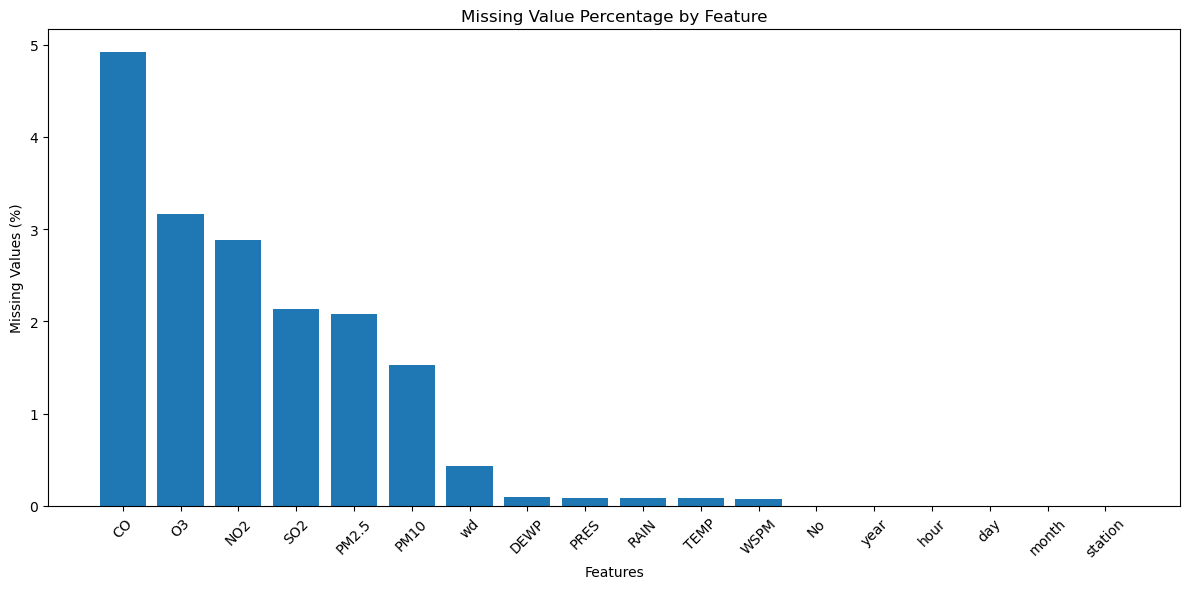

In [22]:
import matplotlib.pyplot as plt

missing_percentage_sorted = missing_percentage.sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    missing_percentage_sorted.index,
    missing_percentage_sorted.values
)

plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.title("Missing Value Percentage by Feature")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 3.3 CHECK DUPLICATE RECORDS

Duplicate observations can affect statistical analysis and machine learning models.

We will check whether completely identical rows exist in the master dataset.

In [23]:
duplicate_count = master_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 3.4 CHECK DATA TYPES

We will verify the data type of each column.

Correct data types are important for numerical analysis, datetime operations, feature engineering, and machine learning.

In [24]:
print(master_df.dtypes)

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object


## 3.5 CHECK BASIC STATISTICS

We will examine the basic statistical properties of the numerical variables.

This will help us understand the range, central tendency, and spread of the environmental measurements before handling potential outliers.

In [25]:
master_df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0


## 3.6 CHECK CATEGORICAL FEATURES

The dataset contains categorical variables such as wind direction and station name.

We will inspect their unique values before deciding how they should be represented for machine learning.

In [26]:
print("Wind directions:")
print(master_df["wd"].unique())

print("\nNumber of wind directions:")
print(master_df["wd"].nunique())

print("\nMonitoring stations:")
print(master_df["station"].unique())

print("\nNumber of stations:")
print(master_df["station"].nunique())

Wind directions:
['NNW' 'N' 'NW' 'NNE' 'ENE' 'E' 'NE' 'W' 'SSW' 'WSW' 'SE' 'WNW' 'SSE'
 'ESE' 'S' 'SW' nan]

Number of wind directions:
16

Monitoring stations:
['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']

Number of stations:
12


## 3.7 CREATE DATETIME COLUMN

The master dataset stores year, month, day, and hour separately.

We will combine these components into a single datetime column for all monitoring stations.

This datetime column will later be used to create daily environmental profiles.

In [27]:
master_df["datetime"] = pd.to_datetime(
    master_df[["year", "month", "day", "hour"]]
)

print("Datetime column created successfully.")

Datetime column created successfully.


## 3.8 VERIFY DATETIME RANGE

We will verify the earliest and latest timestamps in the complete master dataset.

In [28]:
print("First observation:")
print(master_df["datetime"].min())

print("\nLast observation:")
print(master_df["datetime"].max())

First observation:
2013-03-01 00:00:00

Last observation:
2017-02-28 23:00:00


## 3.9 ANALYZE MISSING VALUES BY STATION

Missing values may not be distributed equally across the 12 monitoring stations.

We will examine the missing values for each station separately before applying any imputation method.

This is important because environmental measurements should be interpolated within the same monitoring station and not across different stations.

In [29]:
# Calculate missing values for each feature at each station

missing_by_station = master_df.groupby("station").apply(
    lambda x: x.isnull().sum()
)

missing_by_station

C:\Users\hukup\AppData\Local\Temp\ipykernel_34572\2531650891.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_by_station = master_df.groupby("station").apply(


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
station,,,,,,,,,,,,,,,,,,,
Aotizhongxin,0,0,0,0,0,925,718,935,1023,1776,1719,20,20,20,20,81,14,0,0
Changping,0,0,0,0,0,774,582,628,667,1521,604,53,50,53,51,140,43,0,0
Dingling,0,0,0,0,0,779,656,730,1234,2012,1214,53,50,53,51,140,43,0,0
Dongsi,0,0,0,0,0,750,553,663,1601,3197,664,20,20,20,20,78,14,0,0
Guanyuan,0,0,0,0,0,616,429,474,659,1753,1173,20,20,20,20,81,14,0,0
Gucheng,0,0,0,0,0,646,381,507,668,1401,729,51,50,51,43,159,42,0,0
Huairou,0,0,0,0,0,953,777,980,1639,1422,1151,51,53,53,55,302,49,0,0
Nongzhanguan,0,0,0,0,0,628,440,446,692,1206,506,20,20,20,20,78,14,0,0
Shunyi,0,0,0,0,0,913,548,1296,1365,2178,1489,51,51,54,51,483,44,0,0


## 3.10 MISSING VALUE PERCENTAGE BY STATION

We will calculate the percentage of missing values for each feature at each monitoring station.

This will help us identify whether any particular station has substantially more missing data than the others.

In [30]:
# Calculate missing-value percentage for each feature at each station

missing_percentage_by_station = (
    master_df.groupby("station")
    .apply(lambda x: x.isnull().mean() * 100)
    .round(2)
)

missing_percentage_by_station


C:\Users\hukup\AppData\Local\Temp\ipykernel_34572\2770930407.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.isnull().mean() * 100)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
station,,,,,,,,,,,,,,,,,,,
Aotizhongxin,0.0,0.0,0.0,0.0,0.0,2.64,2.05,2.67,2.92,5.07,4.90,0.06,0.06,0.06,0.06,0.23,0.04,0.0,0.0
Changping,0.0,0.0,0.0,0.0,0.0,2.21,1.66,1.79,1.90,4.34,1.72,0.15,0.14,0.15,0.15,0.40,0.12,0.0,0.0
Dingling,0.0,0.0,0.0,0.0,0.0,2.22,1.87,2.08,3.52,5.74,3.46,0.15,0.14,0.15,0.15,0.40,0.12,0.0,0.0
Dongsi,0.0,0.0,0.0,0.0,0.0,2.14,1.58,1.89,4.57,9.12,1.89,0.06,0.06,0.06,0.06,0.22,0.04,0.0,0.0
Guanyuan,0.0,0.0,0.0,0.0,0.0,1.76,1.22,1.35,1.88,5.00,3.35,0.06,0.06,0.06,0.06,0.23,0.04,0.0,0.0
Gucheng,0.0,0.0,0.0,0.0,0.0,1.84,1.09,1.45,1.91,4.00,2.08,0.15,0.14,0.15,0.12,0.45,0.12,0.0,0.0
Huairou,0.0,0.0,0.0,0.0,0.0,2.72,2.22,2.79,4.67,4.06,3.28,0.15,0.15,0.15,0.16,0.86,0.14,0.0,0.0
Nongzhanguan,0.0,0.0,0.0,0.0,0.0,1.79,1.25,1.27,1.97,3.44,1.44,0.06,0.06,0.06,0.06,0.22,0.04,0.0,0.0
Shunyi,0.0,0.0,0.0,0.0,0.0,2.60,1.56,3.70,3.89,6.21,4.25,0.15,0.15,0.15,0.15,1.38,0.13,0.0,0.0


## 3.11 SORT DATA BY STATION AND TIME

Before handling missing values, the master dataset must be ordered by monitoring station and datetime.

This ensures that time-based interpolation is performed correctly within each individual monitoring station.

In [31]:
# Sort the master dataset by station and datetime

master_df = master_df.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

print("Dataset sorted successfully.")

Dataset sorted successfully.


## 3.12 IDENTIFY NUMERICAL ENVIRONMENTAL FEATURES

The air-quality and meteorological measurements will be treated as numerical features.

These variables will later be used for feature engineering and anomaly detection.

In [32]:
numerical_features = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

print("Numerical environmental features:")
print(numerical_features)

Numerical environmental features:
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']


## 3.13 HANDLE MISSING NUMERICAL VALUES

Missing values in numerical environmental measurements will be estimated using time-based interpolation within each monitoring station.

This approach uses the surrounding observations in the same station to estimate missing hourly measurements while preserving the temporal pattern of the data.

In [33]:
# Interpolate numerical features within each station

for feature in numerical_features:
    master_df[feature] = (
        master_df.groupby("station")[feature]
        .transform(
            lambda x: x.interpolate(
                method="linear",
                limit_direction="both"
            )
        )
    )

print("Missing numerical values handled using interpolation.")

Missing numerical values handled using interpolation.


## 3.14 HANDLE MISSING WIND DIRECTION

Wind direction is a categorical variable and cannot be interpolated numerically.

Missing wind-direction values will be filled using the nearest available observation within the same monitoring station.

In [34]:
# Fill missing wind directions within each station

master_df["wd"] = (
    master_df.groupby("station")["wd"]
    .transform(
        lambda x: x.ffill().bfill()
    )
)

print("Missing wind-direction values handled.")

Missing wind-direction values handled.


## 3.15 VERIFY MISSING VALUES AFTER CLEANING

After handling the missing values, we will verify the dataset again.

This will confirm whether any missing values remain.

In [35]:
remaining_missing = master_df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

print("Remaining missing values:")
print(remaining_missing)

Remaining missing values:
Series([], dtype: int64)


## 3.16 CHECK FOR INVALID NUMERICAL VALUES

Before proceeding to feature engineering, we will check whether the environmental measurements contain physically invalid values.

Extreme values are not automatically considered errors because unusual environmental conditions are important for our anomaly-detection objective.

Therefore, we will identify potentially invalid values first and investigate them before making any changes.

In [36]:
# Check for negative values in environmental measurements

for feature in numerical_features:
    negative_count = (master_df[feature] < 0).sum()
    
    print(f"{feature}: {negative_count} negative values")

PM2.5: 0 negative values
PM10: 0 negative values
SO2: 0 negative values
NO2: 0 negative values
CO: 0 negative values
O3: 0 negative values
TEMP: 64383 negative values
PRES: 0 negative values
DEWP: 185694 negative values
RAIN: 0 negative values
WSPM: 0 negative values


## 3.17 CHECK NON-NEGATIVE ENVIRONMENTAL FEATURES

Certain environmental measurements cannot have negative values.

We will specifically check these features for negative observations rather than applying the same rule to every numerical variable.

In [37]:
# Features that should not contain negative values

non_negative_features = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "PRES",
    "RAIN",
    "WSPM"
]

for feature in non_negative_features:
    negative_count = (master_df[feature] < 0).sum()
    
    print(f"{feature}: {negative_count} negative values")

PM2.5: 0 negative values
PM10: 0 negative values
SO2: 0 negative values
NO2: 0 negative values
CO: 0 negative values
O3: 0 negative values
PRES: 0 negative values
RAIN: 0 negative values
WSPM: 0 negative values


## 3.18 CHECK ZERO VALUES

Zero values can represent valid environmental conditions, such as no rainfall.

We will examine the frequency of zero values without treating them as missing or invalid.

In [38]:
for feature in numerical_features:
    zero_count = (master_df[feature] == 0).sum()
    
    print(f"{feature}: {zero_count} zero values")

PM2.5: 0 zero values
PM10: 0 zero values
SO2: 0 zero values
NO2: 0 zero values
CO: 0 zero values
O3: 0 zero values
TEMP: 2746 zero values
PRES: 0 zero values
DEWP: 832 zero values
RAIN: 404241 zero values
WSPM: 11120 zero values


## 3.19 INSPECT EXTREME VALUES

The project aims to detect unusual environmental conditions.

Therefore, extreme values should not automatically be removed as outliers.

Instead, we will examine high percentile values to understand the distribution of each environmental feature before deciding whether any values require correction.

In [39]:
percentile_summary = master_df[numerical_features].quantile(
    [0.01, 0.50, 0.95, 0.99, 1.00]
).T

percentile_summary.columns = [
    "1%",
    "50%",
    "95%",
    "99%",
    "100%"
]

percentile_summary

,1%,50%,95%,99%,100%
PM2.5,3.0,55.0,242.0,372.0,999.0
PM10,5.0,82.0,280.0,427.0,999.0
SO2,2.0,7.0,61.0,104.0,500.0
NO2,2.0,43.0,117.0,157.0,290.0
CO,100.0,900.0,3500.0,6000.0,10000.0
O3,1.0,44.0,178.0,246.0,1071.0
TEMP,-7.9,14.5,30.6,33.8,41.6
PRES,990.4,1010.4,1027.9,1032.5,1042.8
DEWP,-24.8,3.0,22.1,24.5,29.1
RAIN,0.0,0.0,0.0,1.4,72.5


## 3.20 DATA QUALITY DECISION

The dataset contains no negative values in features that should be non-negative, indicating no obvious physically invalid measurements based on this check.

Several environmental variables contain extreme values. These values will not be removed at this stage because unusual environmental conditions are the primary focus of this project.

Instead of treating extreme observations as errors, the project will preserve them for the anomaly-detection stage.

Potential sensor-limit or recording-related extreme values may be investigated separately during the exploratory analysis.

## 3.21 DATA CLEANING SUMMARY

The initial data-cleaning process has been completed.

The master dataset contains observations from all 12 monitoring stations. Missing numerical values were handled using station-wise interpolation, missing categorical wind-direction values were filled using nearby observations within each station, and no duplicate records were found.

The dataset also contains no negative values in the environmental features that should be non-negative.

Extreme environmental values have been retained because they may represent genuine unusual conditions and are relevant to the project's anomaly-detection objective.

In [40]:
print("Final dataset shape:", master_df.shape)
print("Total missing values:", master_df.isnull().sum().sum())
print("Total duplicate rows:", master_df.duplicated().sum())
print("Number of stations:", master_df["station"].nunique())

Final dataset shape: (420768, 19)
Total missing values: 0
Total duplicate rows: 0
Number of stations: 12


# STEP 4 — DAILY ENVIRONMENTAL PROFILE CREATION

The cleaned master dataset contains hourly observations from 12 monitoring stations.

Our project aims to detect unusual environmental days rather than individual unusual hours.

Therefore, the hourly measurements will be aggregated into daily environmental profiles.

For each station and day, we will calculate suitable daily statistics such as mean, maximum, minimum, and total values for the environmental variables.

## 4.1 CHECK HOURLY OBSERVATIONS PER DAY

Before creating daily profiles, we will examine how many hourly observations are available for each station and day.

A complete day should normally contain 24 hourly observations.

In [41]:
# Count hourly observations for each station and date

hourly_count = (
    master_df
    .groupby([
        "station",
        master_df["datetime"].dt.date
    ])
    .size()
)

print("Minimum hourly observations in a station-day:",
      hourly_count.min())

print("Maximum hourly observations in a station-day:",
      hourly_count.max())

print("Average hourly observations in a station-day:",
      round(hourly_count.mean(), 2))

Minimum hourly observations in a station-day: 24
Maximum hourly observations in a station-day: 24
Average hourly observations in a station-day: 24.0


## 4.2 IDENTIFY INCOMPLETE DAYS

Some station-days may contain fewer than 24 hourly observations.

We will count these incomplete days before creating the daily dataset.

In [42]:
# Identify station-days with fewer than 24 hourly observations

incomplete_days = hourly_count[hourly_count < 24]

print("Number of incomplete station-days:",
      len(incomplete_days))


Number of incomplete station-days: 0


## 4.3 CREATE DATE COLUMN

A separate date column will be created from the datetime column.

This column will be used to group hourly observations into daily environmental profiles.

In [43]:
# Create date column

master_df["date"] = master_df["datetime"].dt.date

print("Date column created successfully.")

Date column created successfully.


## 4.4 DEFINE DAILY AGGREGATION METHODS

Different environmental variables require different daily aggregation methods.

For pollutant concentrations and meteorological measurements, daily mean values will represent the overall daily condition.

For rainfall, the daily total will represent the amount of rainfall received during the day.

Maximum values will also be retained for pollutants to capture unusually high pollution levels during a day.

| Feature | Daily aggregation | 
|---------|-------------------|
| PM2.5   | Mean + Maximum    |
| PM10    | Mean + Maximum    |
| SO₂     | Mean + Maximum    |
| NO₂     | Mean + Maximum    |
| CO      | Mean + Maximum    |
| O₃      | Mean + Maximum    |
| TEMP    | Mean              |
| PRES    | Mean              |
| DEWP    | Mean              |
| RAIN    | **Sum**           |
| WSPM    | Mean              |

## 4.5 CREATE DAILY ENVIRONMENTAL PROFILES

The hourly observations will now be aggregated by monitoring station and date.

The resulting dataset will contain one row for each station-day.

This daily dataset will be used for exploratory analysis and later anomaly detection.

In [44]:
# Create daily environmental profiles

daily_df = (
    master_df
    .groupby(["station", "date"])
    .agg({
        "PM2.5": ["mean", "max"],
        "PM10": ["mean", "max"],
        "SO2": ["mean", "max"],
        "NO2": ["mean", "max"],
        "CO": ["mean", "max"],
        "O3": ["mean", "max"],
        "TEMP": "mean",
        "PRES": "mean",
        "DEWP": "mean",
        "RAIN": "sum",
        "WSPM": "mean"
    })
    .reset_index()
)

print("Daily dataset shape:", daily_df.shape)

Daily dataset shape: (17532, 19)


## 4.6 SIMPLIFY DAILY FEATURE NAMES

The aggregation operation creates multi-level column names.

We will convert them into simple feature names so that they are easier to use during visualization and machine learning.

In [45]:
# Flatten multi-level column names

daily_df.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple)
    else col
    for col in daily_df.columns
]

print("Daily feature names:")
display(daily_df.columns.tolist())

Daily feature names:


['station',
 'date',
 'PM2.5_mean',
 'PM2.5_max',
 'PM10_mean',
 'PM10_max',
 'SO2_mean',
 'SO2_max',
 'NO2_mean',
 'NO2_max',
 'CO_mean',
 'CO_max',
 'O3_mean',
 'O3_max',
 'TEMP_mean',
 'PRES_mean',
 'DEWP_mean',
 'RAIN_sum',
 'WSPM_mean']

## 4.7 INSPECT THE DAILY DATASET

We will now inspect the size and sample records of the newly created daily environmental dataset.

In [46]:
print("Daily dataset shape:")
print(daily_df.shape)

print("\nFirst 5 daily profiles:")
display(daily_df.head())

Daily dataset shape:
(17532, 19)

First 5 daily profiles:


,station,date,PM2.5_mean,PM2.5_max,PM10_mean,PM10_max,SO2_mean,SO2_max,NO2_mean,NO2_max,CO_mean,CO_max,O3_mean,O3_max,TEMP_mean,PRES_mean,DEWP_mean,RAIN_sum,WSPM_mean
0,Aotizhongxin,2013-03-01,7.125000,24.0,10.750000,24.0,11.708333,26.0,22.583333,57.0,429.166667,700.0,63.875000,77.0,1.391667,1026.875000,-18.745833,0.0,3.254167
1,Aotizhongxin,2013-03-02,30.750000,93.0,42.083333,120.0,36.625000,87.0,66.666667,110.0,824.916667,1700.0,29.750000,52.0,0.616667,1026.850000,-15.937500,0.0,1.479167
2,Aotizhongxin,2013-03-03,76.916667,117.0,120.541667,181.0,61.291667,135.0,81.000000,135.0,1620.625000,2799.0,19.125000,77.0,5.566667,1014.608333,-12.316667,0.0,1.658333
3,Aotizhongxin,2013-03-04,22.708333,58.0,44.583333,94.0,22.854167,51.0,46.187500,86.0,606.250000,1300.0,53.750000,84.0,9.962500,1017.650000,-11.683333,0.0,2.404167
4,Aotizhongxin,2013-03-05,148.875000,226.0,183.791667,269.0,93.875000,147.0,132.833333,204.0,2357.958333,4400.0,68.458333,84.0,6.291667,1010.900000,-7.525000,0.0,1.129167


## 4.8 CHECK DAILY DATASET QUALITY

After aggregation, we will verify that the daily dataset does not contain unexpected missing values.

In [47]:
daily_missing = daily_df.isnull().sum()

print("Missing values in daily dataset:")
print(daily_missing[daily_missing > 0])

Missing values in daily dataset:
Series([], dtype: int64)


# STEP 5 — CITY-LEVEL DAILY PROFILE CREATION

The station-level daily dataset contains one record for each monitoring station and day.

To detect city-level environmental anomalies, we will create a second dataset containing one record per day.

Before aggregating the stations, we will verify that all 12 monitoring stations are represented for each day.

In [48]:
# Count stations available for each day

station_count_per_day = (
    daily_df
    .groupby("date")["station"]
    .nunique()
)

print("Minimum stations available on a day:",
      station_count_per_day.min())

print("Maximum stations available on a day:",
      station_count_per_day.max())

print("Average stations available per day:",
      round(station_count_per_day.mean(), 2))

Minimum stations available on a day: 12
Maximum stations available on a day: 12
Average stations available per day: 12.0


## 5.2 CHECK UNIQUE DAYS

We will verify the total number of unique days available in the daily dataset.

In [49]:
print("Number of unique days:",
      daily_df["date"].nunique())

print("Number of monitoring stations:",
      daily_df["station"].nunique())

Number of unique days: 1461
Number of monitoring stations: 12


## 5.3 DEFINE CITY-LEVEL AGGREGATION

The 12 monitoring stations will be combined for each day.

For environmental measurements, the city-level mean will represent the overall condition.

The maximum will capture the highest observed station value.

The standard deviation will measure how much environmental conditions differ between monitoring stations.

## 5.4 CREATE CITY-LEVEL DATASET

In [50]:
# Features to aggregate across monitoring stations

city_features = [
    "PM2.5_mean",
    "PM2.5_max",
    "PM10_mean",
    "PM10_max",
    "SO2_mean",
    "SO2_max",
    "NO2_mean",
    "NO2_max",
    "CO_mean",
    "CO_max",
    "O3_mean",
    "O3_max",
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]

# Calculate city-level statistics

city_daily_df = (
    daily_df
    .groupby("date")[city_features]
    .agg(["mean", "max", "std"])
    .reset_index()
)

print("City-level dataset shape:",
      city_daily_df.shape)

City-level dataset shape: (1461, 52)


## 5.5 CREATE CLEAN CITY-LEVEL FEATURES

The initial city-level aggregation generated multiple statistics for both daily mean and daily maximum measurements.

To avoid redundant features, a simplified city-level dataset will be created.

The dataset will retain:

- Overall environmental conditions
- Highest station-level pollution
- Variation between monitoring stations
- Daily meteorological conditions

This representation will be used for exploratory analysis and machine learning.

In [51]:
# Create clean city-level daily features

city_daily_df = (
    daily_df
    .groupby("date")
    .agg(
        PM2_5_mean=("PM2.5_mean", "mean"),
        PM2_5_max=("PM2.5_max", "max"),
        PM2_5_std=("PM2.5_mean", "std"),

        PM10_mean=("PM10_mean", "mean"),
        PM10_max=("PM10_max", "max"),
        PM10_std=("PM10_mean", "std"),

        SO2_mean=("SO2_mean", "mean"),
        SO2_max=("SO2_max", "max"),
        SO2_std=("SO2_mean", "std"),

        NO2_mean=("NO2_mean", "mean"),
        NO2_max=("NO2_max", "max"),
        NO2_std=("NO2_mean", "std"),

        CO_mean=("CO_mean", "mean"),
        CO_max=("CO_max", "max"),
        CO_std=("CO_mean", "std"),

        O3_mean=("O3_mean", "mean"),
        O3_max=("O3_max", "max"),
        O3_std=("O3_mean", "std"),

        TEMP_mean=("TEMP_mean", "mean"),
        PRES_mean=("PRES_mean", "mean"),
        DEWP_mean=("DEWP_mean", "mean"),
        RAIN_sum=("RAIN_sum", "sum"),
        WSPM_mean=("WSPM_mean", "mean")
    )
    .reset_index()
)

print("Clean city-level dataset shape:", city_daily_df.shape)

Clean city-level dataset shape: (1461, 24)


## 5.6 INSPECT CITY-LEVEL DAILY DATASET

The final city-level daily dataset will be inspected to verify the feature structure and sample records.

In [52]:
print("Shape:", city_daily_df.shape)

print("\nColumns:")
display(city_daily_df.columns.tolist())

print("\nFirst 5 records:")
display(city_daily_df.head())

Shape: (1461, 24)

Columns:


['date',
 'PM2_5_mean',
 'PM2_5_max',
 'PM2_5_std',
 'PM10_mean',
 'PM10_max',
 'PM10_std',
 'SO2_mean',
 'SO2_max',
 'SO2_std',
 'NO2_mean',
 'NO2_max',
 'NO2_std',
 'CO_mean',
 'CO_max',
 'CO_std',
 'O3_mean',
 'O3_max',
 'O3_std',
 'TEMP_mean',
 'PRES_mean',
 'DEWP_mean',
 'RAIN_sum',
 'WSPM_mean']


First 5 records:


,date,PM2_5_mean,PM2_5_max,PM2_5_std,PM10_mean,PM10_max,PM10_std,SO2_mean,SO2_max,SO2_std,...,CO_max,CO_std,O3_mean,O3_max,O3_std,TEMP_mean,PRES_mean,DEWP_mean,RAIN_sum,WSPM_mean
0,2013-03-01,7.326389,24.0,1.068641,12.203125,101.0,3.466358,9.182292,50.0,4.069774,...,1200.0,156.794086,68.244792,94.0,10.402142,1.173958,1026.569792,-20.148611,0.0,2.917708
1,2013-03-02,31.475694,130.0,2.755072,40.506944,147.0,4.146840,31.757878,87.0,6.377025,...,2899.0,181.148485,32.601112,89.0,6.987123,0.260417,1026.552778,-16.271875,0.0,1.145139
2,2013-03-03,79.291667,152.0,18.735803,111.104167,294.0,23.721983,49.286458,161.0,14.837717,...,4400.0,511.988117,22.788194,94.0,9.073571,5.257292,1014.215278,-12.325347,0.0,1.463194
3,2013-03-04,21.768569,88.0,2.558067,40.359375,156.0,7.368380,18.818692,70.0,5.224779,...,4200.0,203.275816,56.833333,107.0,11.809849,9.610764,1017.263194,-12.773264,0.0,2.227083
4,2013-03-05,125.352959,270.0,31.435902,159.236111,343.0,26.446202,70.756944,147.0,17.823063,...,4799.0,526.796124,79.527778,107.0,11.935450,6.630556,1010.551389,-7.916319,0.0,0.992014


## 5.7 VERIFY CITY-LEVEL DATASET

The city-level dataset will be checked for missing values and duplicate dates before proceeding to exploratory analysis.

In [53]:
print("Total missing values:",
      city_daily_df.isnull().sum().sum())

print("Duplicate dates:",
      city_daily_df["date"].duplicated().sum())

print("Number of days:",
      city_daily_df["date"].nunique())

Total missing values: 0
Duplicate dates: 0
Number of days: 1461


# STEP 6 — EXPLORATORY DATA ANALYSIS

Exploratory Data Analysis will be performed on the city-level daily dataset to understand the environmental patterns across Beijing from 2013 to 2017.

The analysis will examine pollutant levels, weather conditions, temporal patterns, feature relationships, and unusual observations.

These observations will help us understand the dataset before applying unsupervised machine learning techniques for anomaly detection.

## 6.1 DESCRIPTIVE STATISTICS

The descriptive statistics of the city-level environmental features will be examined to understand their central tendency, variability, and range.

In [54]:
# Generate descriptive statistics

city_daily_df.describe().T

,count,mean,std,min,25%,50%,75%,max
PM2_5_mean,1461.0,79.839718,67.263721,5.428819,31.791667,61.312500,106.302083,473.050347
PM2_5_max,1461.0,194.710428,130.211717,15.000000,104.000000,164.000000,253.000000,999.000000
PM2_5_std,1461.0,13.341326,12.122271,0.828863,5.794428,9.841317,16.770176,114.636354
PM10_mean,1461.0,104.910268,71.825468,6.531250,50.447917,89.611111,137.100694,495.888889
PM10_max,1461.0,290.491794,163.476426,28.000000,181.000000,253.000000,349.000000,999.000000
PM10_std,1461.0,18.334077,12.710726,1.356117,10.100866,15.447404,22.574959,126.516766
SO2_mean,1461.0,15.913090,17.475314,2.003472,4.472222,9.328125,20.555556,128.687500
SO2_max,1461.0,55.820379,55.571536,3.000000,21.000000,37.000000,71.000000,500.000000
SO2_std,1461.0,4.653224,4.727422,0.012028,1.741940,3.294608,5.943782,77.257989
NO2_mean,1461.0,50.599018,24.052864,8.309318,33.651042,44.378472,62.696625,153.253472


## 6.2 CHECK CITY-LEVEL DATA TYPES

The data types of the city-level features will be inspected to ensure that numerical features are correctly represented before visualization and machine learning.

In [55]:
print(city_daily_df.dtypes)

date           object
PM2_5_mean    float64
PM2_5_max     float64
PM2_5_std     float64
PM10_mean     float64
PM10_max      float64
PM10_std      float64
SO2_mean      float64
SO2_max       float64
SO2_std       float64
NO2_mean      float64
NO2_max       float64
NO2_std       float64
CO_mean       float64
CO_max        float64
CO_std        float64
O3_mean       float64
O3_max        float64
O3_std        float64
TEMP_mean     float64
PRES_mean     float64
DEWP_mean     float64
RAIN_sum      float64
WSPM_mean     float64
dtype: object


## 6.3 CONVERT DATE TO DATETIME

The date column will be converted into datetime format so that time-based analysis and visualization can be performed correctly.

In [56]:
# Convert date column to datetime

city_daily_df["date"] = pd.to_datetime(city_daily_df["date"])

print("Date data type:",
      city_daily_df["date"].dtype)

Date data type: datetime64[ns]


## 6.4 CHECK CITY DATASET TIME RANGE

The minimum and maximum dates will be checked to confirm the complete time period covered by the city-level dataset.

In [57]:
print("Start date:", city_daily_df["date"].min())
print("End date:", city_daily_df["date"].max())

Start date: 2013-03-01 00:00:00
End date: 2017-02-28 00:00:00


## 6.5 PM2.5 DAILY TREND

The daily average PM2.5 concentration will be visualized over time to identify long-term patterns, seasonal changes, and unusually high pollution periods.

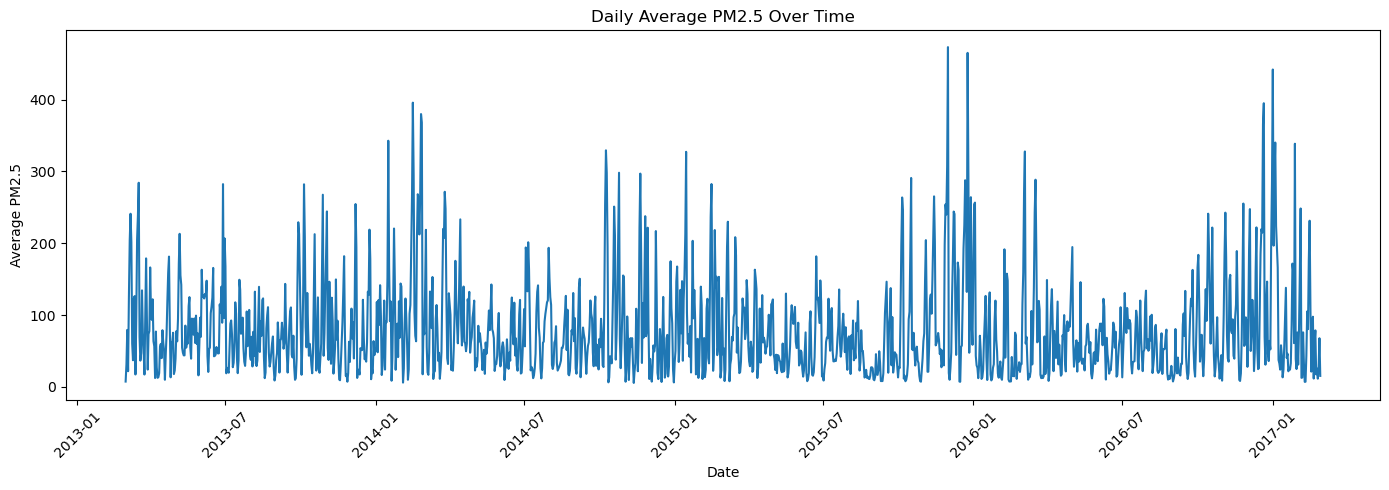

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    city_daily_df["date"],
    city_daily_df["PM2_5_mean"]
)

plt.xlabel("Date")
plt.ylabel("Average PM2.5")
plt.title("Daily Average PM2.5 Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6.6 PM10 DAILY TREND

The daily average PM10 concentration will be visualized to examine its temporal behavior and identify periods of unusually high particulate pollution.

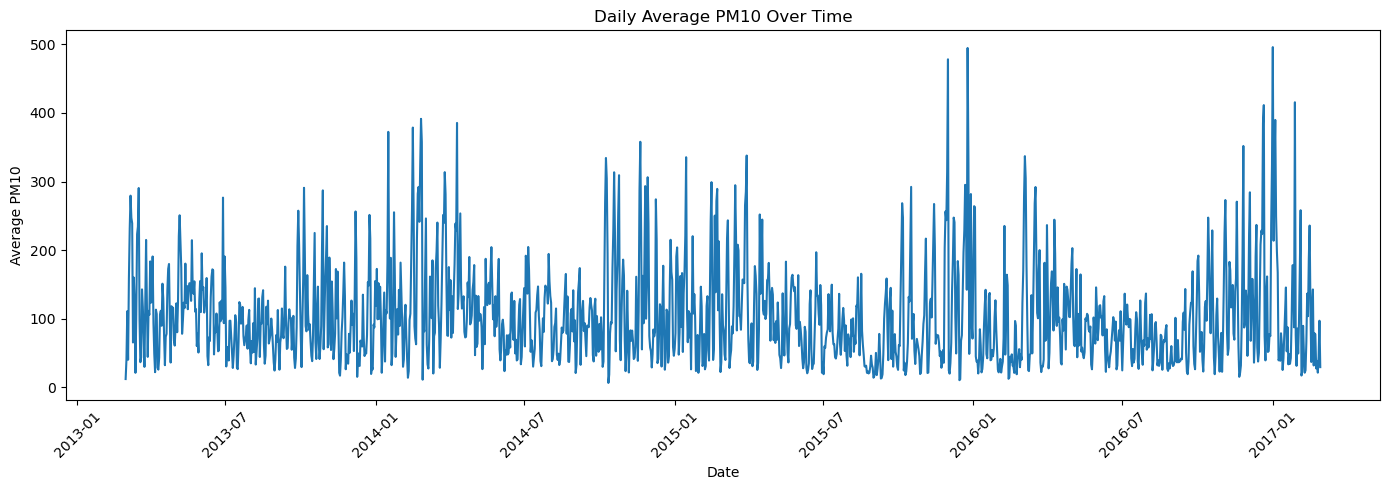

In [59]:
plt.figure(figsize=(14, 5))

plt.plot(
    city_daily_df["date"],
    city_daily_df["PM10_mean"]
)

plt.xlabel("Date")
plt.ylabel("Average PM10")
plt.title("Daily Average PM10 Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6.7 TEMPERATURE DAILY TREND

The daily average temperature will be visualized to understand seasonal patterns and their relationship with environmental conditions.

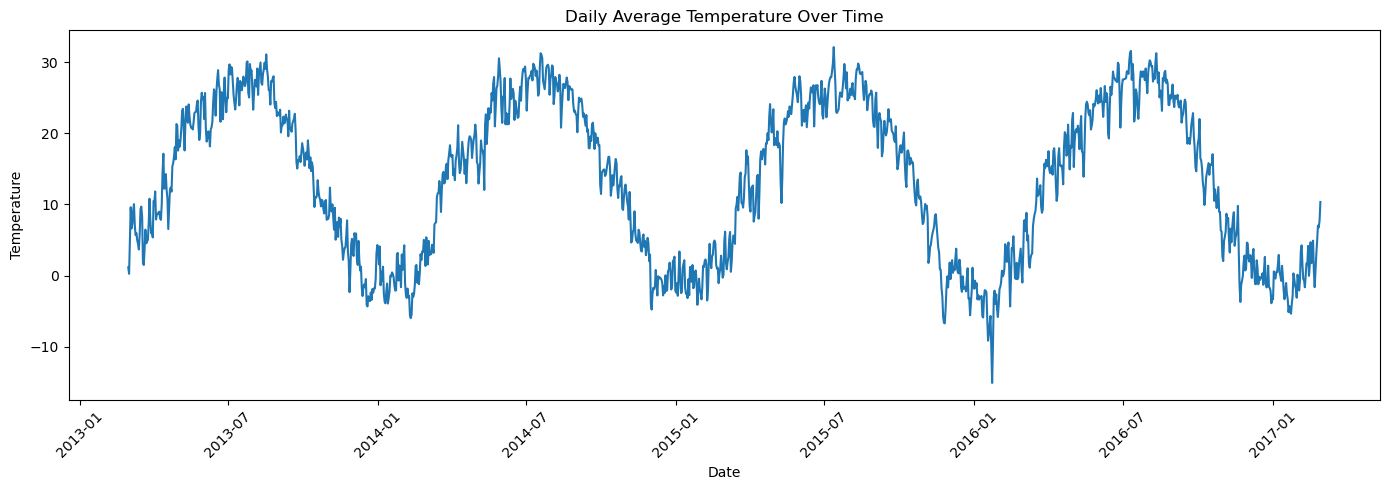

In [60]:
plt.figure(figsize=(14, 5))

plt.plot(
    city_daily_df["date"],
    city_daily_df["TEMP_mean"]
)

plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("Daily Average Temperature Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6.8 POLLUTANT DISTRIBUTIONS

The distributions of the major air pollutants will be examined to understand their typical ranges, variability, and extreme values.

This will help identify whether the environmental features contain skewed or highly variable observations that may influence anomaly detection.

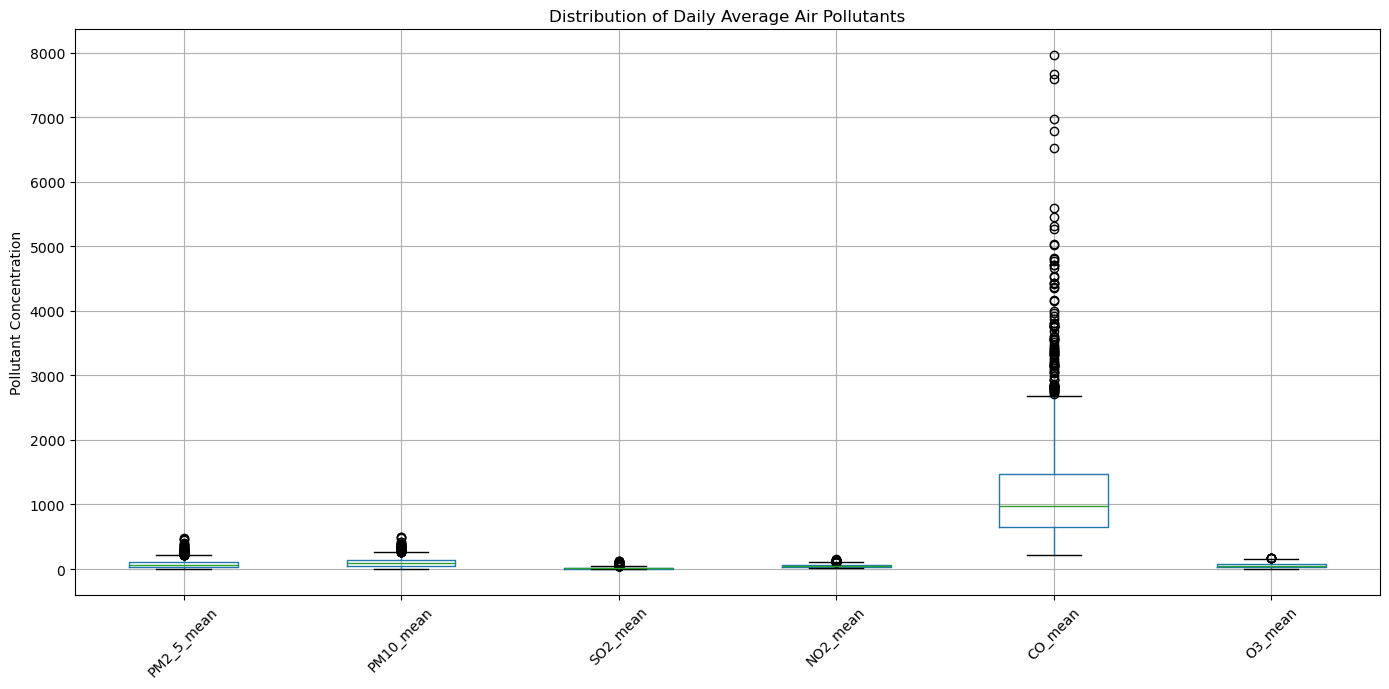

In [61]:
pollutants = [
    "PM2_5_mean",
    "PM10_mean",
    "SO2_mean",
    "NO2_mean",
    "CO_mean",
    "O3_mean"
]

plt.figure(figsize=(14, 7))

city_daily_df[pollutants].boxplot()

plt.title("Distribution of Daily Average Air Pollutants")
plt.ylabel("Pollutant Concentration")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6.9 WEATHER FEATURE DISTRIBUTIONS

The distributions of temperature, pressure, dew point, rainfall, and wind speed will be examined to understand their variability and identify extreme observations.

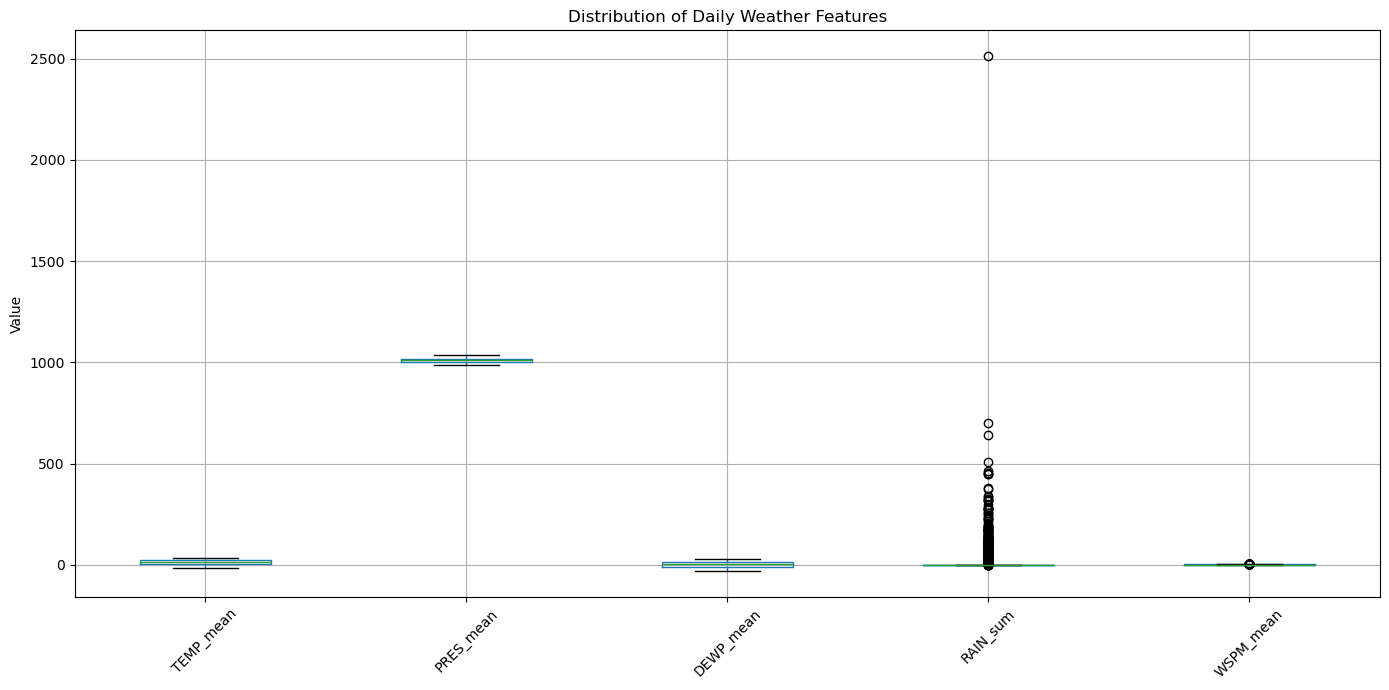

In [62]:
weather_features = [
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]

plt.figure(figsize=(14, 7))

city_daily_df[weather_features].boxplot()

plt.title("Distribution of Daily Weather Features")
plt.ylabel("Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6.10 FEATURE CORRELATION ANALYSIS

The correlation between environmental variables will be examined to identify relationships between pollutants and meteorological conditions.

This analysis will help us understand feature relationships before applying machine learning.

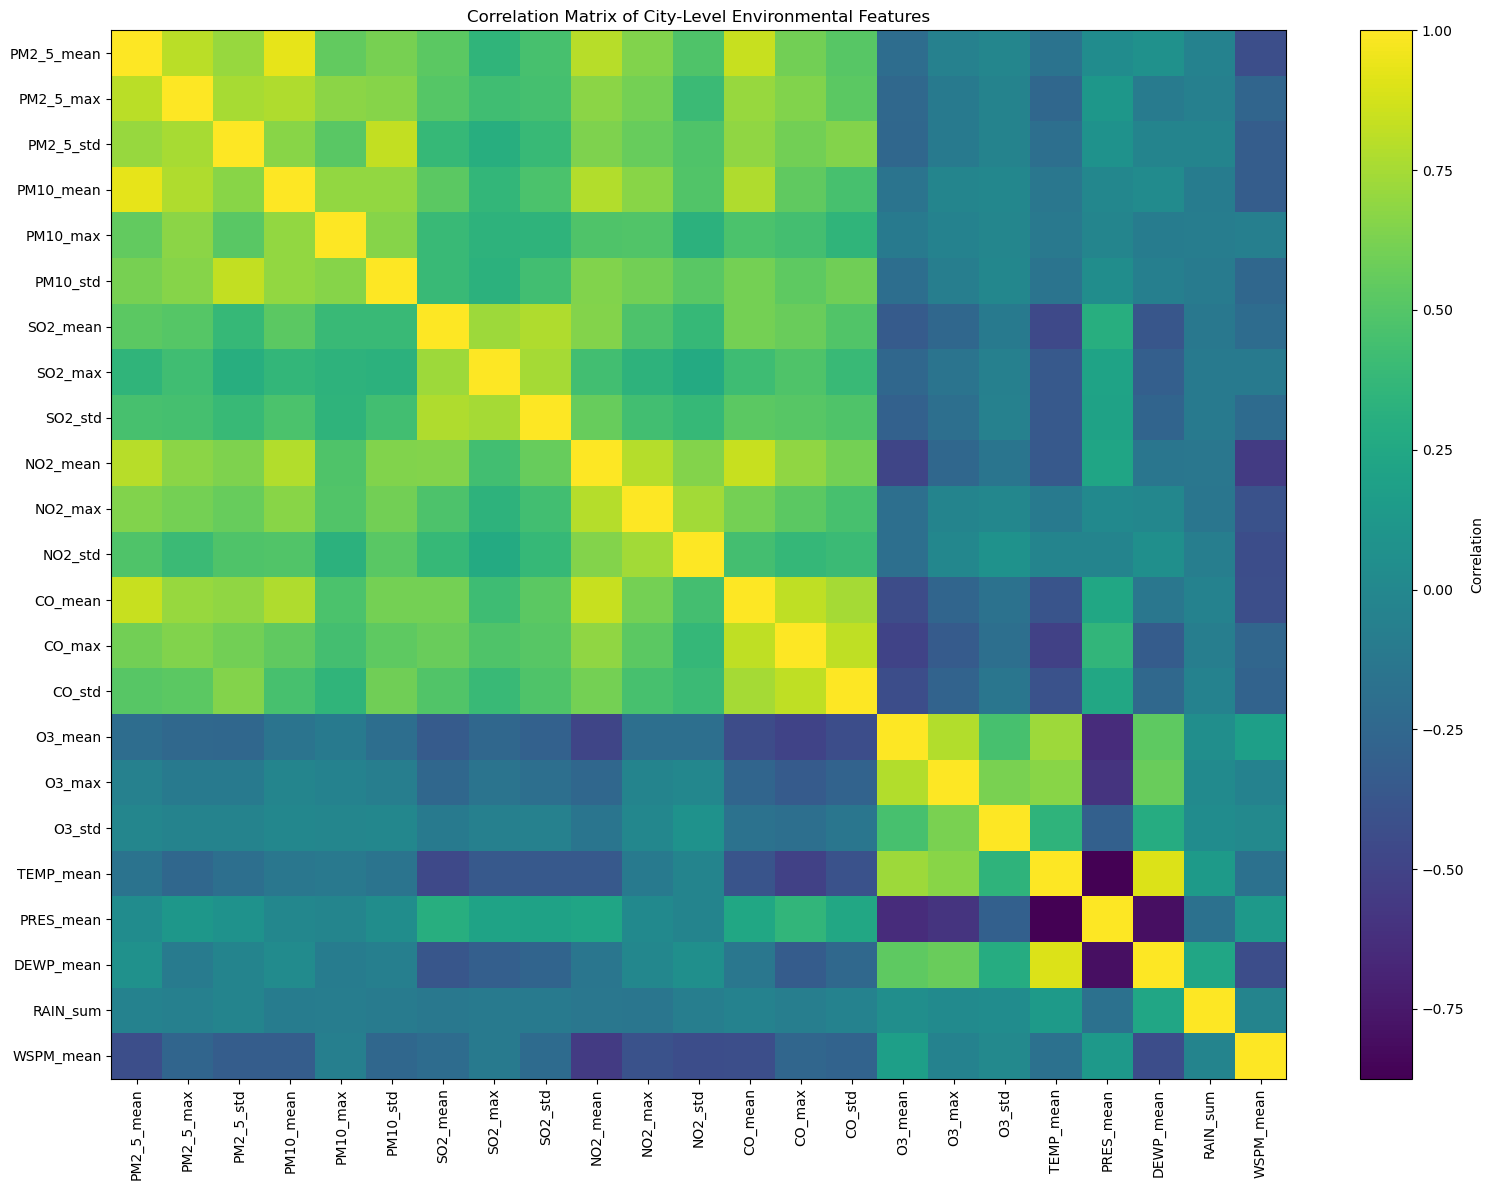

In [63]:
feature_columns = [
    "PM2_5_mean",
    "PM2_5_max",
    "PM2_5_std",
    "PM10_mean",
    "PM10_max",
    "PM10_std",
    "SO2_mean",
    "SO2_max",
    "SO2_std",
    "NO2_mean",
    "NO2_max",
    "NO2_std",
    "CO_mean",
    "CO_max",
    "CO_std",
    "O3_mean",
    "O3_max",
    "O3_std",
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]

correlation_matrix = city_daily_df[feature_columns].corr()

plt.figure(figsize=(16, 12))

plt.imshow(
    correlation_matrix,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=90
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns
)

plt.title("Correlation Matrix of City-Level Environmental Features")

plt.tight_layout()
plt.show()

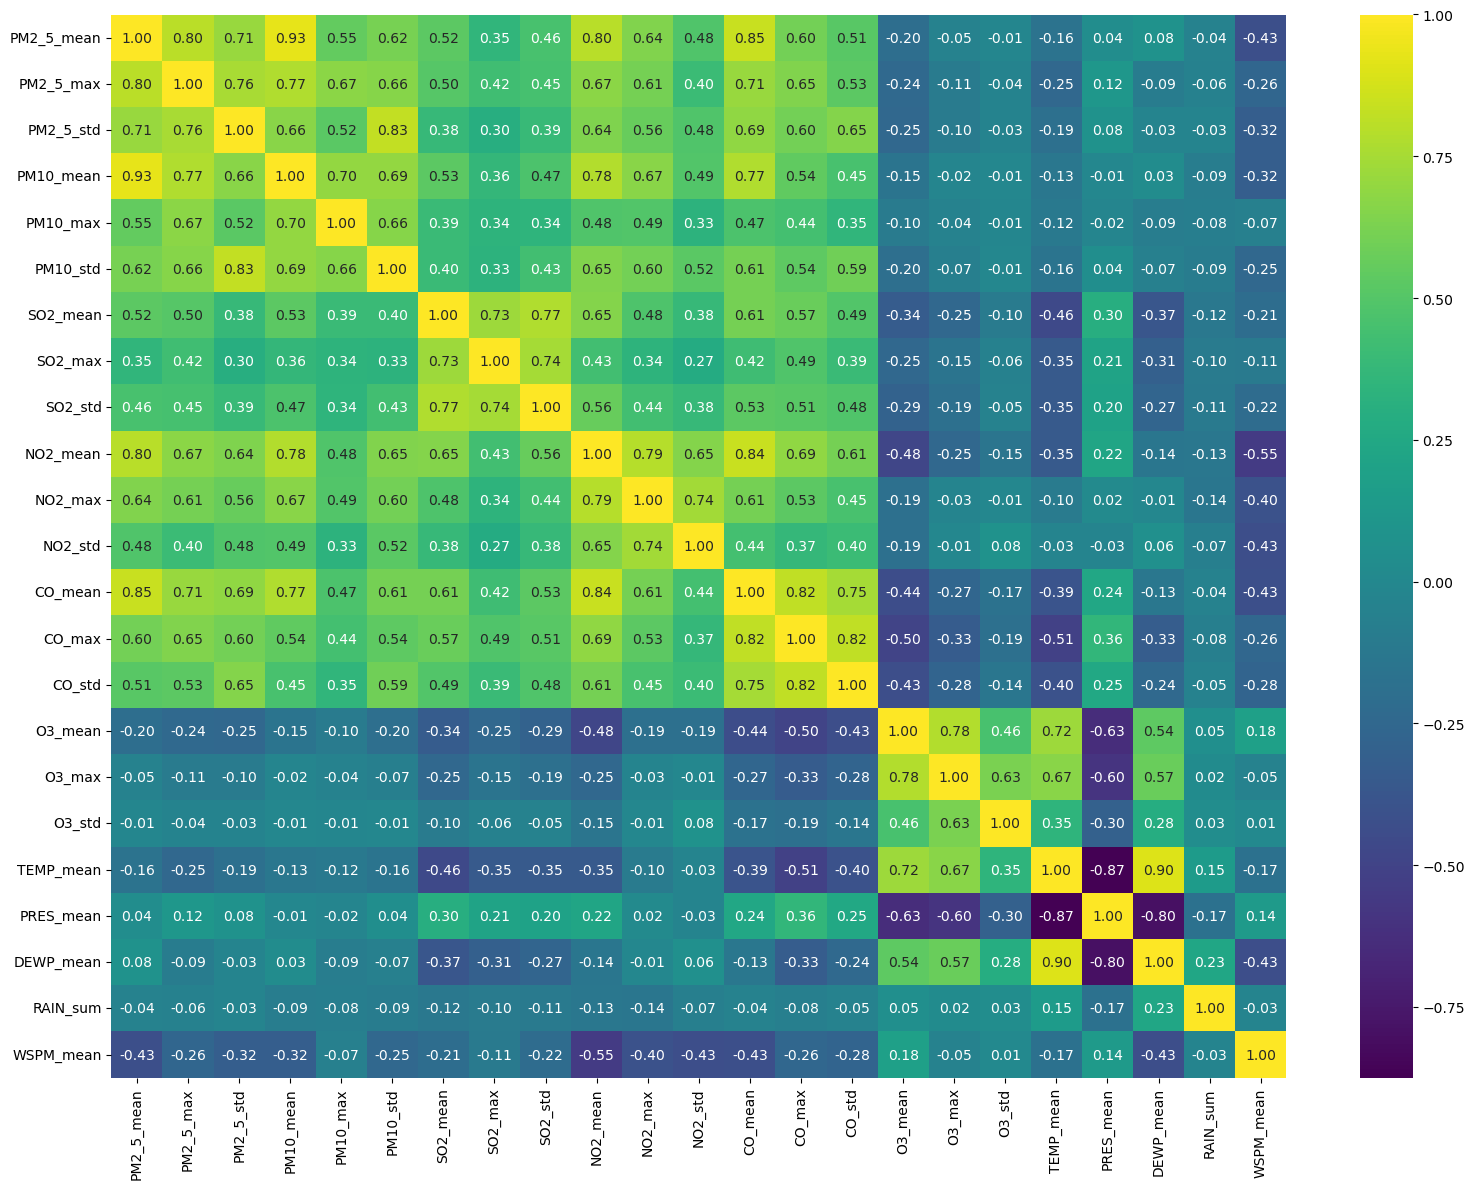

In [64]:
import seaborn as sns
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.tight_layout()
plt.show()

## 6.11 STRONG FEATURE RELATIONSHIPS

The strongest correlations between environmental features will be identified to understand the relationships present in the dataset.

In [65]:
corr_pairs = (
    correlation_matrix
    .where(
        ~correlation_matrix.eq(1)
    )
    .stack()
    .sort_values(
        ascending=False
    )
)

print("Top positive correlations:")
print(corr_pairs.head(15))

print("\nTop negative correlations:")
print(corr_pairs.tail(15))

Top positive correlations:
PM2_5_mean  PM10_mean     0.927982
PM10_mean   PM2_5_mean    0.927982
TEMP_mean   DEWP_mean     0.901643
DEWP_mean   TEMP_mean     0.901643
CO_mean     PM2_5_mean    0.845685
PM2_5_mean  CO_mean       0.845685
CO_mean     NO2_mean      0.841084
NO2_mean    CO_mean       0.841084
PM2_5_std   PM10_std      0.826354
PM10_std    PM2_5_std     0.826354
CO_mean     CO_max        0.818396
CO_max      CO_mean       0.818396
            CO_std        0.817587
CO_std      CO_max        0.817587
PM2_5_max   PM2_5_mean    0.804100
dtype: float64

Top negative correlations:
O3_mean    NO2_mean    -0.483168
CO_max     O3_mean     -0.500575
O3_mean    CO_max      -0.500575
CO_max     TEMP_mean   -0.513092
TEMP_mean  CO_max      -0.513092
WSPM_mean  NO2_mean    -0.549907
NO2_mean   WSPM_mean   -0.549907
PRES_mean  O3_max      -0.596252
O3_max     PRES_mean   -0.596252
O3_mean    PRES_mean   -0.633921
PRES_mean  O3_mean     -0.633921
DEWP_mean  PRES_mean   -0.796480
PRES_mean

## 6.12 CORRELATION ANALYSIS CONCLUSION

The correlation analysis shows strong relationships among several environmental variables.

PM2.5 and PM10 show a very strong positive correlation, while temperature and dew point are also strongly correlated. Several pollutants such as CO, PM2.5, and PM10 show positive relationships.

Some variables, particularly O3 and atmospheric variables such as temperature and pressure, show negative relationships.

Highly correlated features will not be removed solely based on correlation because the project focuses on multivariate anomaly detection. Different environmental variables may provide important information about unusual environmental patterns.

Dimensionality reduction using PCA will be evaluated later for clustering, while the original standardized features will be retained for interpretable anomaly analysis.

# STEP 7 — MACHINE LEARNING FEATURE PREPARATION

The exploratory analysis is now complete.

The city-level daily dataset will be converted into a machine learning feature matrix.

The date column will be retained separately for identifying anomalous days, but it will not be used as a machine learning feature.

The environmental features will be standardized before applying unsupervised machine learning algorithms.

## 7.1 Select environmental features for machine learning

In [66]:
ml_features = [
    "PM2_5_mean",
    "PM2_5_max",
    "PM2_5_std",
    "PM10_mean",
    "PM10_max",
    "PM10_std",
    "SO2_mean",
    "SO2_max",
    "SO2_std",
    "NO2_mean",
    "NO2_max",
    "NO2_std",
    "CO_mean",
    "CO_max",
    "CO_std",
    "O3_mean",
    "O3_max",
    "O3_std",
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]

X = city_daily_df[ml_features].copy()

dates = city_daily_df["date"].copy()

print("ML feature matrix shape:", X.shape)
print("Number of ML features:", len(ml_features))

ML feature matrix shape: (1461, 23)
Number of ML features: 23


## 7.2 VERIFY ML FEATURE MATRIX

The machine learning feature matrix will be checked to ensure that all selected features are numerical and contain no missing values before scaling.

In [67]:
print("Data types:")
print(X.dtypes)

print("\nTotal missing values:")
print(X.isnull().sum().sum())

print("\nFeature matrix shape:")
print(X.shape)

Data types:
PM2_5_mean    float64
PM2_5_max     float64
PM2_5_std     float64
PM10_mean     float64
PM10_max      float64
PM10_std      float64
SO2_mean      float64
SO2_max       float64
SO2_std       float64
NO2_mean      float64
NO2_max       float64
NO2_std       float64
CO_mean       float64
CO_max        float64
CO_std        float64
O3_mean       float64
O3_max        float64
O3_std        float64
TEMP_mean     float64
PRES_mean     float64
DEWP_mean     float64
RAIN_sum      float64
WSPM_mean     float64
dtype: object

Total missing values:
0

Feature matrix shape:
(1461, 23)


## 7.3 CHECK FEATURE SCALE

The ranges of the machine learning features will be examined before standardization.

The environmental variables have very different numerical scales, so scaling will be required before distance-based clustering.

In [68]:
feature_scale_summary = X.describe().T[
    ["min", "mean", "max", "std"]
]

feature_scale_summary

,min,mean,max,std
PM2_5_mean,5.428819,79.839718,473.050347,67.263721
PM2_5_max,15.000000,194.710428,999.000000,130.211717
PM2_5_std,0.828863,13.341326,114.636354,12.122271
PM10_mean,6.531250,104.910268,495.888889,71.825468
PM10_max,28.000000,290.491794,999.000000,163.476426
PM10_std,1.356117,18.334077,126.516766,12.710726
SO2_mean,2.003472,15.913090,128.687500,17.475314
SO2_max,3.000000,55.820379,500.000000,55.571536
SO2_std,0.012028,4.653224,77.257989,4.727422
NO2_mean,8.309318,50.599018,153.253472,24.052864


## 7.4 STANDARDIZE MACHINE LEARNING FEATURES

The selected environmental features have different numerical scales.

Standardization will transform the features so that they have approximately zero mean and unit standard deviation.

This prevents features with larger numerical values from dominating distance-based machine learning algorithms such as K-Means.

In [69]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the ML features
X_scaled = scaler.fit_transform(X)

print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (1461, 23)


## 7.5 VERIFY STANDARDIZED FEATURES

The mean and standard deviation of the standardized features will be checked to confirm that the scaling was performed correctly.

In [70]:
scaled_summary = pd.DataFrame(
    X_scaled,
    columns=ml_features
).agg(["mean", "std"]).T

scaled_summary

,mean,std
PM2_5_mean,-1.945360e-17,1.000342
PM2_5_max,-1.556288e-16,1.000342
PM2_5_std,-2.431700e-17,1.000342
PM10_mean,-1.896726e-16,1.000342
PM10_max,2.918040e-17,1.000342
PM10_std,7.781440e-17,1.000342
SO2_mean,-3.890720e-17,1.000342
SO2_max,-9.726800e-17,1.000342
SO2_std,-3.890720e-17,1.000342
NO2_mean,-9.726800e-17,1.000342


## 7.6 PCA AND EXPLAINED VARIANCE

Principal Component Analysis (PCA) will be used to examine the underlying dimensionality of the standardized environmental features.

PCA transforms the original correlated features into principal components that capture the maximum possible variance in the data.

The explained variance will be examined to determine how much information is retained by each component.

In [71]:
from sklearn.decomposition import PCA

# Fit PCA using all standardized features
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of principal components:", X_pca.shape[1])

Original number of features: 23
Number of principal components: 23


## 7.7 EXPLAINED VARIANCE RATIO

The explained variance ratio of each principal component will be calculated to understand how much information each component contributes.

In [72]:
explained_variance = pca.explained_variance_ratio_

explained_variance_df = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": explained_variance.cumsum()
})

explained_variance_df

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.421338,0.421338
1,PC2,0.179768,0.601106
2,PC3,0.068431,0.669537
3,PC4,0.057154,0.726691
4,PC5,0.046358,0.773049
5,PC6,0.038720,0.811769
6,PC7,0.033445,0.845214
7,PC8,0.030994,0.876208
8,PC9,0.021266,0.897474
9,PC10,0.017629,0.915103


## 7.8 PCA EXPLAINED VARIANCE PLOT

A scree plot will be used to visualize the explained variance of the principal components and identify how quickly the information is concentrated in the first few components.

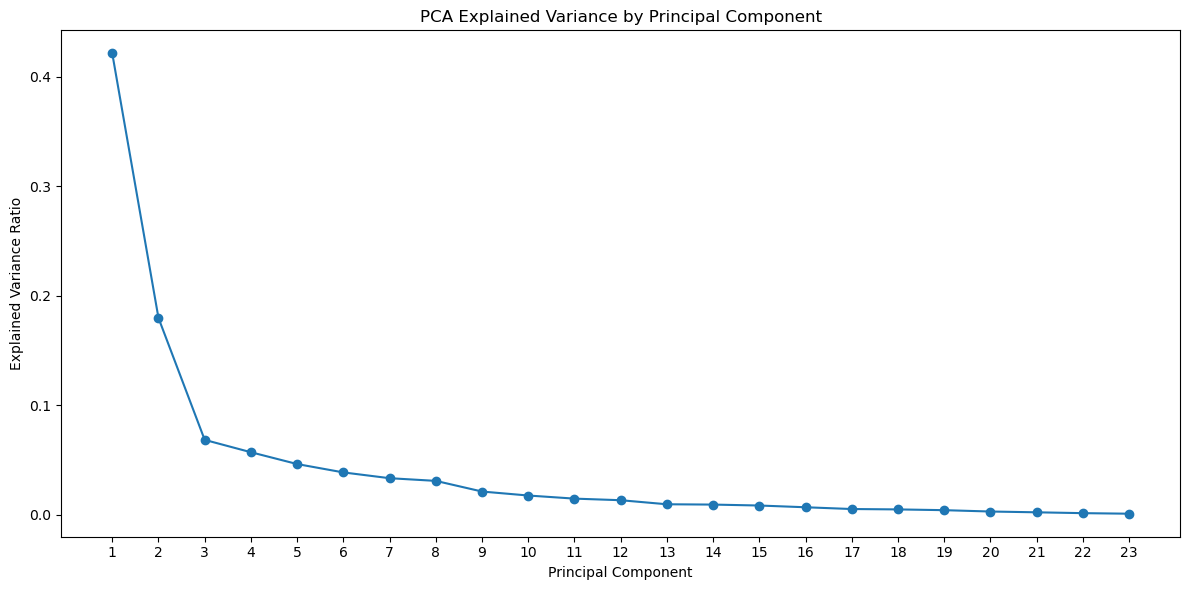

In [73]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance by Principal Component")

plt.xticks(range(1, len(explained_variance) + 1))

plt.tight_layout()
plt.show()

## 7.9 CUMULATIVE EXPLAINED VARIANCE

The cumulative explained variance will be examined to determine how many principal components are required to retain most of the information contained in the original 23 features.

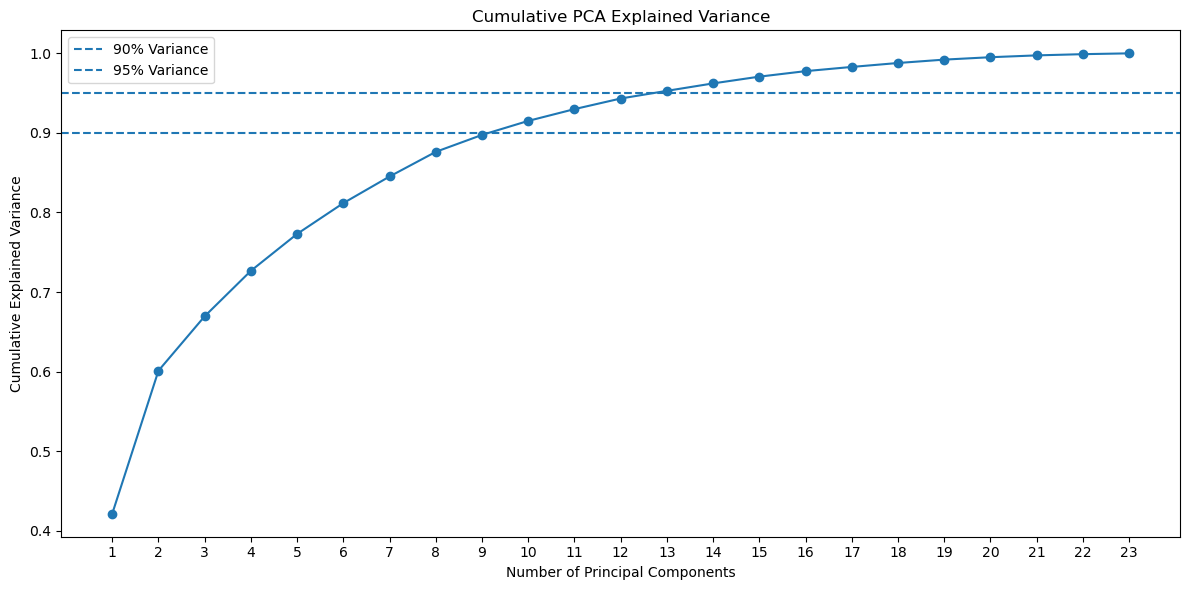

In [74]:
cumulative_variance = explained_variance.cumsum()

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% Variance"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative PCA Explained Variance")

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()

plt.tight_layout()
plt.show()

## 7.10 CREATE REDUCED PCA FEATURE MATRIX

The PCA analysis showed that 13 principal components retain approximately 95% of the total variance.

Therefore, a 13-component PCA representation will be created for the clustering stage.

The original standardized feature matrix will also be retained for later anomaly interpretation.

In [75]:
# Create PCA representation with 13 components

pca_13 = PCA(n_components=13)

X_pca_13 = pca_13.fit_transform(X_scaled)

print("Original feature dimensions:", X_scaled.shape)
print("PCA feature dimensions:", X_pca_13.shape)

print(
    "Cumulative explained variance:",
    round(pca_13.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original feature dimensions: (1461, 23)
PCA feature dimensions: (1461, 13)
Cumulative explained variance: 95.29 %


## 7.11 VERIFY PCA FEATURE MATRIX

The dimensions and basic structure of the reduced PCA feature matrix will be checked before applying clustering.

In [76]:
print("PCA matrix shape:", X_pca_13.shape)

print("\nFirst 5 PCA records:")
display(
    pd.DataFrame(
        X_pca_13,
        columns=[f"PC{i}" for i in range(1, 14)]
    ).head()
)

PCA matrix shape: (1461, 13)

First 5 PCA records:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-3.042211,-3.483189,1.193464,0.210956,-0.137240,0.521771,0.147036,-0.250317,0.192718,-0.761185,-0.146405,-0.175745,-0.325502
1,-0.340286,-2.995721,0.262261,-1.666766,-0.267017,-0.012519,-0.279060,-0.796313,-0.327000,0.024437,0.753484,-0.672445,0.423902
2,3.229931,-1.388596,1.276968,-2.132084,0.150539,0.030205,0.541813,0.899658,-0.079515,-0.206397,-0.437721,-0.198795,-0.030410
3,-1.201826,-1.974770,0.768192,-0.735514,-0.297525,0.473245,0.271196,0.099434,0.741290,0.127707,0.141416,0.131239,0.145886
4,5.393763,0.588705,1.635998,-2.638229,-0.451326,0.000708,1.198430,0.522318,0.504153,-1.016764,-0.194896,-0.492545,0.624431


# STEP 8 — K-MEANS CLUSTERING
## 8.1 — INTRODUCTION TO K-MEANS

K-Means clustering will be used to identify different types of environmental days in Beijing.

The algorithm will group days with similar environmental characteristics into clusters.

Since the number of clusters is not known beforehand, different values of K will be evaluated using the Elbow Method and Silhouette Score.

## 8.2 IMPORT K-MEANS

The K-Means clustering algorithm will be imported from scikit-learn.

In [77]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("K-Means and Silhouette Score imported successfully.")

K-Means and Silhouette Score imported successfully.


## 8.3 TEST DIFFERENT NUMBERS OF CLUSTERS

Different numbers of clusters will be evaluated to determine the most appropriate number of environmental patterns.

K values from 2 to 8 will be tested using K-Means clustering.

In [78]:
# Test different values of K

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_pca_13)
    
    inertia_values.append(kmeans.inertia_)
    
    silhouette_values.append(
        silhouette_score(
            X_pca_13,
            cluster_labels
        )
    )

print("K values tested:", list(k_values))

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K values tested: [2, 3, 4, 5, 6, 7, 8]


## 8.4 CLUSTER EVALUATION RESULTS

The inertia and silhouette score for each tested number of clusters will be stored in a summary table.

In [79]:
cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

cluster_evaluation

,K,Inertia,Silhouette Score
0,2,22586.135776,0.341261
1,3,18758.601630,0.228534
2,4,16693.854904,0.222032
3,5,15583.856016,0.181702
4,6,14696.839625,0.174018
5,7,13895.730009,0.173268
6,8,13212.974823,0.170206


## 8.5 ELBOW METHOD

The Elbow Method will be used to examine how the within-cluster variation decreases as the number of clusters increases.

The point where the reduction in inertia begins to slow down can indicate a suitable number of clusters.

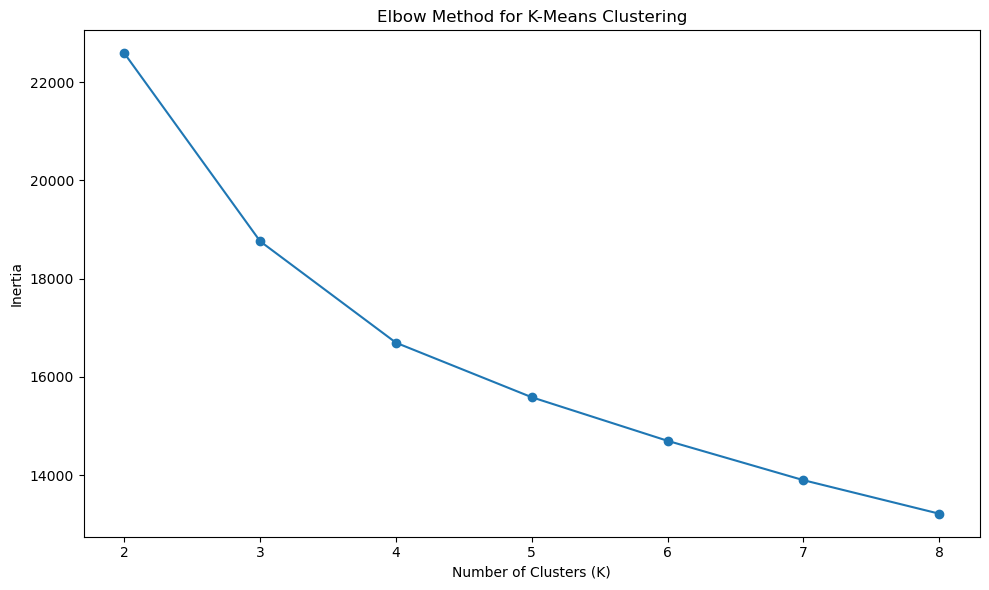

In [80]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

## 8.6 SILHOUETTE SCORE ANALYSIS

The Silhouette Score will be used to evaluate how well-separated the environmental clusters are.

A higher score indicates that observations are more appropriately grouped within their clusters.

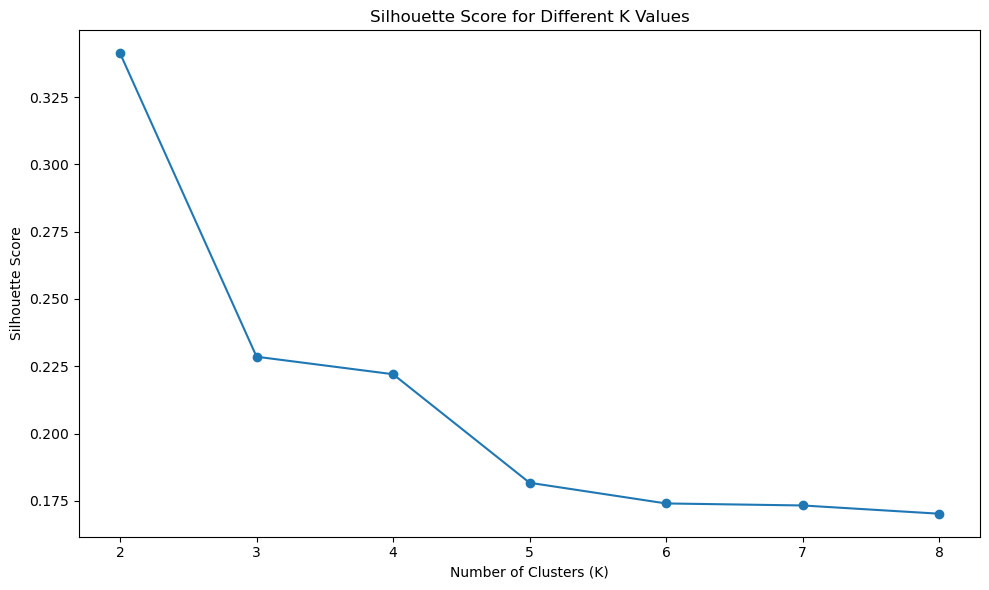

In [81]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

## 8.7 FINAL K-MEANS MODEL

Based on the clustering evaluation, K = 2 provides the highest Silhouette Score among the tested values.

Therefore, a final K-Means model with two clusters will be trained using the 13-component PCA representation.

The resulting clusters will represent two broad environmental regimes identified from the historical data.

In [82]:
# Train final K-Means model with K = 2

optimal_k = 2

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_pca_13)

print("Selected number of clusters:", optimal_k)
print("K-Means clustering completed.")

Selected number of clusters: 2
K-Means clustering completed.


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


## 8.8 ASSIGN CLUSTER LABELS TO CITY DAYS

The K-Means cluster labels will be added to the city-level daily dataset.

This will allow each environmental day to be associated with its corresponding environmental regime.

In [83]:
# Create a copy of the city-level dataset

clustered_df = city_daily_df.copy()

# Add cluster labels
clustered_df["cluster"] = cluster_labels

print("Cluster labels added successfully.")

print("\nCluster counts:")
print(clustered_df["cluster"].value_counts().sort_index())

Cluster labels added successfully.

Cluster counts:
cluster
0     357
1    1104
Name: count, dtype: int64


## 8.9 CHECK CLUSTER DISTRIBUTION

In [84]:
cluster_distribution = (
    clustered_df["cluster"]
    .value_counts()
    .sort_index()
)

cluster_percentage = (
    clustered_df["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

cluster_summary = pd.DataFrame({
    "Number of Days": cluster_distribution,
    "Percentage": cluster_percentage.round(2)
})

cluster_summary

,Number of Days,Percentage
cluster,,
0,357,24.44
1,1104,75.56


## 8.10 ENVIRONMENTAL PROFILE OF EACH CLUSTER

The average environmental characteristics of each cluster will be calculated to understand the type of environmental conditions represented by each cluster.

In [85]:
cluster_profile = (
    clustered_df
    .groupby("cluster")[ml_features]
    .mean()
)

cluster_profile

,PM2_5_mean,PM2_5_max,PM2_5_std,PM10_mean,PM10_max,PM10_std,SO2_mean,SO2_max,SO2_std,NO2_mean,...,CO_max,CO_std,O3_mean,O3_max,O3_std,TEMP_mean,PRES_mean,DEWP_mean,RAIN_sum,WSPM_mean
cluster,,,,,,,,,,,,,,,,,,,,,
0,157.733712,340.331153,25.675114,186.861887,432.166733,30.724270,36.023109,105.116315,9.505502,82.680380,...,5633.008403,507.707893,26.820126,97.693699,9.198763,5.413223,1015.936504,-3.665714,2.499440,1.321640
1,54.651172,147.621117,9.352954,78.409608,244.678431,14.327465,9.410122,39.879573,3.084145,40.224881,...,2344.518726,190.632726,67.074045,165.370503,12.020445,16.156957,1009.077258,4.470541,23.747418,1.862096


## 8.11 COMPLETE ENVIRONMENTAL CLUSTER PROFILE

The environmental characteristics of the two K-Means clusters will be compared across all selected features.

This comparison will help identify the environmental conditions associated with each cluster before performing anomaly detection.

In [86]:
# Create complete cluster profile

cluster_profile = (
    clustered_df
    .groupby("cluster")[ml_features]
    .mean()
)

display(
    cluster_profile.T
)

cluster,0,1
PM2_5_mean,157.733712,54.651172
PM2_5_max,340.331153,147.621117
PM2_5_std,25.675114,9.352954
PM10_mean,186.861887,78.409608
PM10_max,432.166733,244.678431
PM10_std,30.724270,14.327465
SO2_mean,36.023109,9.410122
SO2_max,105.116315,39.879573
SO2_std,9.505502,3.084145
NO2_mean,82.680380,40.224881


## 8.12 — COMPARE CLUSTERS USING RELATIVE VALUES
Because the features have completely different units, a useful next step is to compare the standardized cluster means.

In [87]:
# Calculate standardized cluster profiles

cluster_profile_scaled = (
    pd.DataFrame(
        scaler.transform(cluster_profile),
        columns=ml_features,
        index=cluster_profile.index
    )
)

display(
    cluster_profile_scaled.T
)

cluster,0,1
PM2_5_mean,1.158435,-0.374603
PM2_5_max,1.118721,-0.361760
PM2_5_std,1.017797,-0.329125
PM10_mean,1.141373,-0.369085
PM10_max,0.866935,-0.280340
PM10_std,0.975116,-0.315323
SO2_mean,1.151161,-0.372251
SO2_max,0.887375,-0.286950
SO2_std,1.026762,-0.332024
NO2_mean,1.334242,-0.431453


## 8.13 CLUSTER ENVIRONMENTAL PROFILES

The standardized environmental profiles of the two clusters will be visualized to compare their overall characteristics.

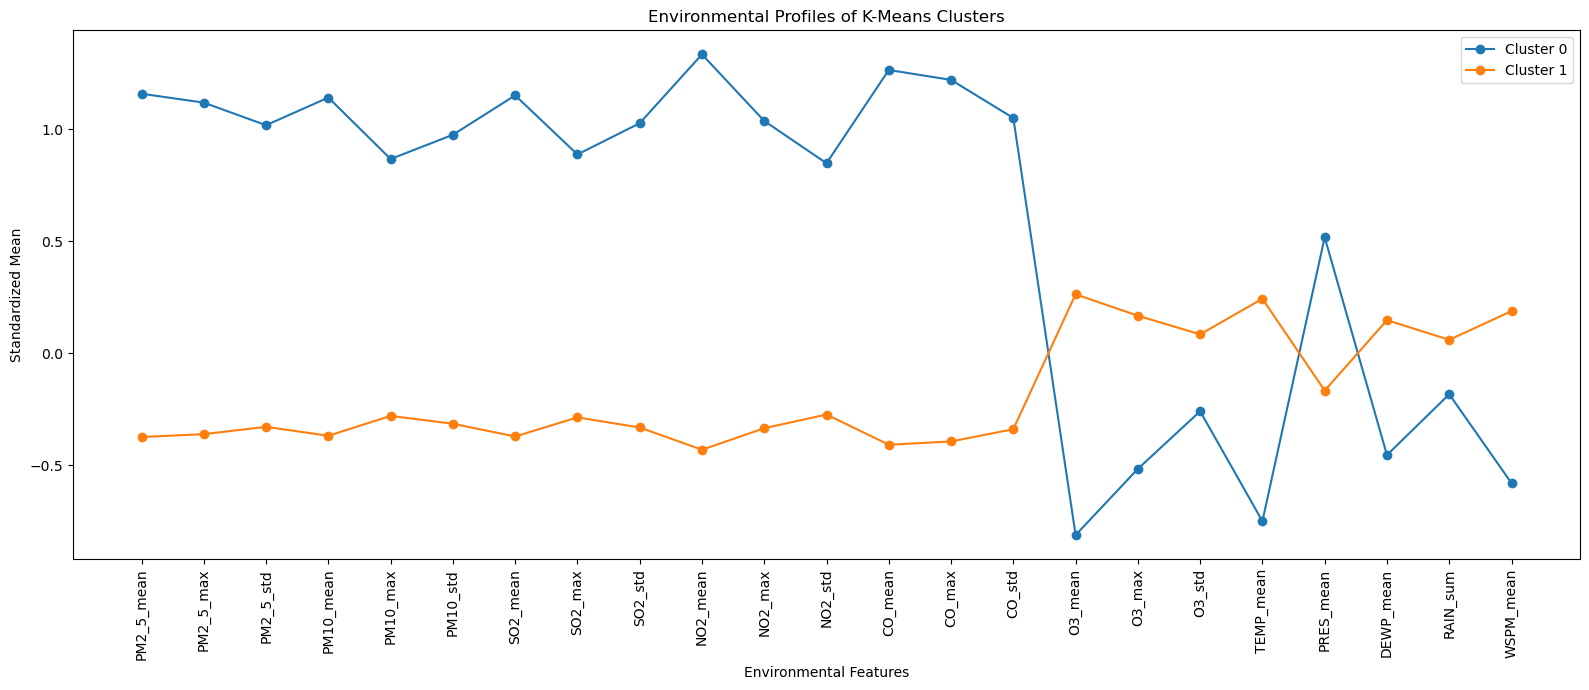

In [88]:
plt.figure(figsize=(16, 7))

plt.plot(
    cluster_profile_scaled.columns,
    cluster_profile_scaled.loc[0],
    marker="o",
    label="Cluster 0"
)

plt.plot(
    cluster_profile_scaled.columns,
    cluster_profile_scaled.loc[1],
    marker="o",
    label="Cluster 1"
)

plt.xlabel("Environmental Features")
plt.ylabel("Standardized Mean")
plt.title("Environmental Profiles of K-Means Clusters")

plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

# STEP 9 — ISOLATION FOREST ANOMALY DETECTION

Isolation Forest will be used to identify unusual environmental days in the city-level dataset.

Unlike K-Means, which identifies groups of similar environmental conditions, Isolation Forest identifies observations that are relatively rare and different from the overall data distribution.

The model will use the standardized environmental features to calculate an anomaly score for each day.

## 9.1 WHY ISOLATION FOREST?

Isolation Forest is suitable for this project because the dataset does not contain predefined labels indicating whether a day is normal or anomalous.

The algorithm isolates unusual observations by randomly partitioning the feature space. Observations that can be isolated using fewer partitions are considered more anomalous.

This allows anomaly detection without requiring manually labelled anomaly data.

## 9.2 PREPARE FEATURES FOR ISOLATION FOREST AND IMPORT ISOLATION FOREST

The original standardized environmental features will be used for Isolation Forest rather than the PCA representation.

Using the original features will make it possible to interpret the environmental characteristics of detected anomalous days.

In [89]:
# Use standardized original features for anomaly detection

X_anomaly = X_scaled.copy()

print("Isolation Forest input shape:", X_anomaly.shape)

from sklearn.ensemble import IsolationForest
print("Isolation Forest imported successfully.")

Isolation Forest input shape: (1461, 23)
Isolation Forest imported successfully.


## 9.3 TRAIN INITIAL ISOLATION FOREST MODEL

An initial Isolation Forest model will be trained using a contamination level of 5%.

The contamination parameter represents the expected proportion of observations considered anomalous by the model.

This value will be treated as an initial modelling assumption and will be evaluated later through anomaly-score analysis and sensitivity testing.

In [90]:
# Train Isolation Forest

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_anomaly)

print("Isolation Forest training completed.")

Isolation Forest training completed.


## 9.4 GENERATE ANOMALY LABELS

The trained Isolation Forest model will assign each city-day an anomaly label.

A label of -1 represents an anomalous observation, while a label of 1 represents a non-anomalous observation.

In [91]:
# Generate anomaly labels

anomaly_labels = isolation_forest.predict(X_anomaly)

print("Anomaly labels generated.")

print("\nUnique labels:")
print(pd.Series(anomaly_labels).value_counts().sort_index())

Anomaly labels generated.

Unique labels:
-1      73
 1    1388
Name: count, dtype: int64


## 9.5 ADD ANOMALY LABELS TO CITY DATA

The anomaly labels will be added to the city-level dataset so that anomalous dates and their environmental conditions can be investigated.

In [92]:
# Create anomaly analysis dataset

anomaly_df = clustered_df.copy()

anomaly_df["anomaly_label"] = anomaly_labels

print("Anomaly labels added successfully.")

print("\nAnomaly distribution:")
print(
    anomaly_df["anomaly_label"]
    .value_counts()
    .sort_index()
)

Anomaly labels added successfully.

Anomaly distribution:
anomaly_label
-1      73
 1    1388
Name: count, dtype: int64


## 9.6 ANOMALY DISTRIBUTION

The number and percentage of observations classified as anomalous will be calculated.

In [93]:
anomaly_count = (
    anomaly_df["anomaly_label"] == -1
).sum()

normal_count = (
    anomaly_df["anomaly_label"] == 1
).sum()

total_days = len(anomaly_df)

anomaly_percentage = (
    anomaly_count / total_days
) * 100

normal_percentage = (
    normal_count / total_days
) * 100

print("Total city-days:", total_days)
print("Normal days:", normal_count)
print("Anomalous days:", anomaly_count)

print(
    "Anomaly percentage:",
    round(anomaly_percentage, 2),
    "%"
)

print(
    "Normal percentage:",
    round(normal_percentage, 2),
    "%"
)

Total city-days: 1461
Normal days: 1388
Anomalous days: 73
Anomaly percentage: 5.0 %
Normal percentage: 95.0 %


## 9.7 CALCULATE ANOMALY SCORES

Isolation Forest decision scores will be calculated for every city-day.

The scores will be used to rank observations according to how unusual they are.

In [94]:
# Calculate Isolation Forest decision scores

anomaly_df["anomaly_score"] = (
    isolation_forest.decision_function(X_anomaly)
)

print("Anomaly scores calculated.")

print(
    anomaly_df["anomaly_score"].describe()
)

Anomaly scores calculated.
count    1461.000000
mean        0.095547
std         0.048563
min        -0.151829
25%         0.076630
50%         0.110081
75%         0.128872
max         0.157085
Name: anomaly_score, dtype: float64


## 9.8 MOST ANOMALOUS ENVIRONMENTAL DAYS

The city-days with the lowest Isolation Forest scores will be identified as the most unusual environmental observations.

In [95]:
# Display the 20 most anomalous days

most_anomalous_days = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .sort_values(
        "anomaly_score",
        ascending=True
    )
)

most_anomalous_days[
    [
        "date",
        "cluster",
        "anomaly_label",
        "anomaly_score"
    ] + ml_features
].head(20)

,date,cluster,anomaly_label,anomaly_score,PM2_5_mean,PM2_5_max,PM2_5_std,PM10_mean,PM10_max,PM10_std,...,CO_max,CO_std,O3_mean,O3_max,O3_std,TEMP_mean,PRES_mean,DEWP_mean,RAIN_sum,WSPM_mean
1405,2017-01-04,0,-1,-0.151829,340.161111,677.0,105.442385,389.756944,857.0,126.516766,...,10000.0,1735.705061,10.315972,68.000000,5.293157,-0.404514,1020.192708,-5.590278,0.0,1.101389
321,2014-01-16,0,-1,-0.141034,342.706597,623.0,81.146204,372.406250,768.0,84.210576,...,8800.0,1044.374448,10.213449,62.000000,5.972311,-0.000347,1021.695833,-8.734375,0.0,1.384722
1029,2015-12-25,0,-1,-0.135242,465.053819,705.0,85.491038,494.640625,771.0,63.101386,...,10000.0,1346.772011,8.519097,33.000000,5.134749,-3.220139,1013.422917,-4.555903,0.0,1.239236
1429,2017-01-28,0,-1,-0.126874,338.513889,835.0,60.268754,415.527778,994.0,76.667657,...,5500.0,370.454174,17.600694,125.000000,16.370266,-1.407344,1016.054745,-11.011458,0.0,1.368750
362,2014-02-26,0,-1,-0.123068,368.119792,592.0,40.415929,357.456597,590.0,36.231208,...,9800.0,821.556681,13.690972,57.000000,9.637785,5.028125,1016.703472,0.007986,10.2,1.377431
1404,2017-01-03,0,-1,-0.123017,289.241667,640.0,71.988404,320.190972,805.0,87.932362,...,9800.0,1403.778280,11.868056,76.000000,5.231323,-0.308333,1016.986806,-6.916667,0.0,0.951736
298,2013-12-24,0,-1,-0.122131,218.892361,424.0,59.503046,251.371528,550.0,74.040974,...,9800.0,1472.890682,6.763622,60.000000,5.529756,-3.404861,1027.432986,-10.117708,0.0,0.995486
1004,2015-11-30,0,-1,-0.120554,307.602431,687.0,114.636354,314.001736,704.0,116.415003,...,9900.0,1633.484942,7.069444,31.000000,3.785411,-1.645486,1019.436806,-3.669097,0.0,1.013889
351,2014-02-15,0,-1,-0.107844,395.722222,809.0,33.423563,378.663194,907.0,53.251068,...,7700.0,558.039595,14.154514,68.000000,11.037133,-1.239931,1018.219097,-6.292708,0.0,1.063889
1390,2016-12-20,0,-1,-0.107810,365.725694,646.0,57.408583,385.215278,708.0,63.680190,...,10000.0,931.588898,5.309028,51.000000,2.500281,-1.282292,1023.131944,-3.668403,0.0,1.148264


## 9.9 ANOMALIES OVER TIME

The detected anomalous days will be visualized across the study period to examine their temporal distribution.

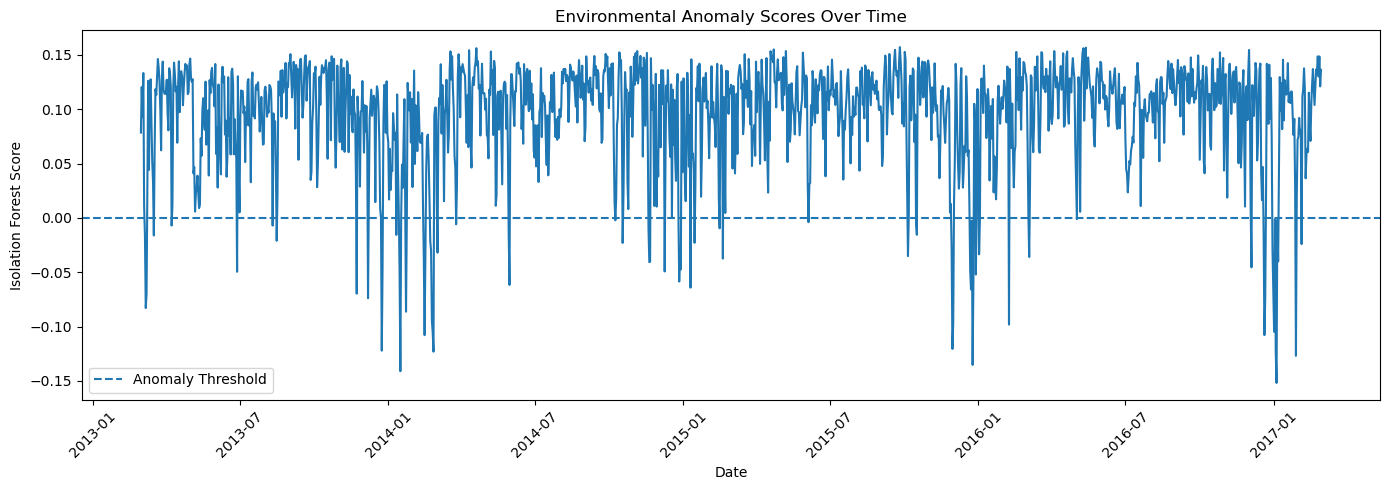

In [96]:
plt.figure(figsize=(14, 5))

plt.plot(
    anomaly_df["date"],
    anomaly_df["anomaly_score"]
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Date")
plt.ylabel("Isolation Forest Score")
plt.title("Environmental Anomaly Scores Over Time")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

## 9.10 YEARLY ANOMALY DISTRIBUTION

The number of detected anomalous days will be calculated for each year to examine whether anomalies are evenly distributed across the study period.

In [97]:
# Extract year

anomaly_df["year"] = anomaly_df["date"].dt.year

yearly_anomalies = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .groupby("year")
    .size()
)

print("Anomalies by year:")
print(yearly_anomalies)

Anomalies by year:
year
2013    12
2014    25
2015    17
2016    11
2017     8
dtype: int64


## 9.11 ANOMALIES BY ENVIRONMENTAL REGIME

The detected anomalous days will be compared with their K-Means environmental cluster to determine which environmental regime contains more anomalies.

In [98]:
anomaly_by_cluster = pd.crosstab(
    anomaly_df["cluster"],
    anomaly_df["anomaly_label"]
)

anomaly_by_cluster.columns = [
    "Normal" if col == 1 else "Anomaly"
    for col in anomaly_by_cluster.columns
]

anomaly_by_cluster

,Anomaly,Normal
cluster,,
0,67,290
1,6,1098


## 9.12 ANOMALY RATE WITHIN EACH ENVIRONMENTAL REGIME

The percentage of anomalous days within each K-Means cluster will be calculated.

This will help compare how frequently unusual environmental patterns occur within each environmental regime.

In [99]:
# Calculate anomaly rate within each cluster

cluster_anomaly_rate = (
    anomaly_df
    .groupby("cluster")["anomaly_label"]
    .apply(lambda x: (x == -1).mean() * 100)
    .round(2)
)

print("Anomaly rate by environmental cluster:")
print(cluster_anomaly_rate)

Anomaly rate by environmental cluster:
cluster
0    18.77
1     0.54
Name: anomaly_label, dtype: float64


## 9.13 OVERALL ANOMALY SUMMARY

A summary of the anomaly detection results will be created for further analysis and reporting.

In [100]:
# Create overall anomaly summary

anomaly_summary = pd.DataFrame({
    "Metric": [
        "Total city-days",
        "Normal days",
        "Anomalous days",
        "Anomaly percentage",
        "Highest anomaly year",
        "Highest anomaly year count"
    ],
    "Value": [
        total_days,
        normal_count,
        anomaly_count,
        round(anomaly_percentage, 2),
        yearly_anomalies.idxmax(),
        yearly_anomalies.max()
    ]
})

anomaly_summary

,Metric,Value
0,Total city-days,1461.0
1,Normal days,1388.0
2,Anomalous days,73.0
3,Anomaly percentage,5.0
4,Highest anomaly year,2014.0
5,Highest anomaly year count,25.0


# STEP 10 — EXPLAINING WHY A DAY IS ANOMALOUS

## 10.1 ANOMALOUS DAY SELECTION

The anomalous observations identified by Isolation Forest will be extracted for detailed analysis.

The most anomalous days will be ranked according to their Isolation Forest anomaly scores.

In [101]:
# Select anomalous days

anomalous_days = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .sort_values(
        "anomaly_score",
        ascending=True
    )
    .copy()
)

print("Number of anomalous days:", len(anomalous_days))

print("\nTop 10 most anomalous days:")

display(
    anomalous_days[
        [
            "date",
            "cluster",
            "anomaly_score"
        ]
    ].head(10)
)

Number of anomalous days: 73

Top 10 most anomalous days:


,date,cluster,anomaly_score
1405,2017-01-04,0,-0.151829
321,2014-01-16,0,-0.141034
1029,2015-12-25,0,-0.135242
1429,2017-01-28,0,-0.126874
362,2014-02-26,0,-0.123068
1404,2017-01-03,0,-0.123017
298,2013-12-24,0,-0.122131
1004,2015-11-30,0,-0.120554
351,2014-02-15,0,-0.107844
1390,2016-12-20,0,-0.107810


## 10.2 NORMAL VS ANOMALOUS ENVIRONMENTAL CONDITIONS

The average environmental characteristics of normal and anomalous days will be compared to identify features that differ substantially between the two groups.

In [102]:
# Compare normal and anomalous days

normal_profile = (
    anomaly_df[
        anomaly_df["anomaly_label"] == 1
    ][ml_features]
    .mean()
)

anomaly_profile = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ][ml_features]
    .mean()
)

comparison_df = pd.DataFrame({
    "Normal Mean": normal_profile,
    "Anomaly Mean": anomaly_profile
})

comparison_df["Difference"] = (
    comparison_df["Anomaly Mean"]
    - comparison_df["Normal Mean"]
)

comparison_df["Absolute Difference"] = (
    comparison_df["Difference"].abs()
)

comparison_df.sort_values(
    "Absolute Difference",
    ascending=False
)

,Normal Mean,Anomaly Mean,Difference,Absolute Difference
CO_max,2919.945731,7485.589041,4565.643311,4565.643311
CO_mean,1109.171863,3641.120612,2531.948749,2531.948749
CO_std,240.097503,800.752231,560.654728,560.654728
PM2_5_max,179.048650,492.498755,313.450105,313.450105
PM10_max,275.304403,579.260274,303.955871,303.955871
PM10_mean,96.336446,267.930324,171.593878,171.593878
PM2_5_mean,71.333243,241.579278,170.246035,170.246035
SO2_max,51.681183,134.521786,82.840603,82.840603
NO2_max,119.402453,200.408355,81.005902,81.005902
NO2_mean,47.951999,100.928638,52.976639,52.976639


## 10.3 RELATIVE FEATURE DIFFERENCE

The relative difference between anomalous and normal days will be calculated to identify features that change substantially during anomalous conditions.    

In [103]:
# Calculate percentage difference
import numpy as np
comparison_df["Percentage Difference"] = (
    (
        comparison_df["Anomaly Mean"]
        - comparison_df["Normal Mean"]
    )
    / comparison_df["Normal Mean"].replace(0, np.nan)
) * 100

comparison_df = comparison_df.sort_values(
    "Percentage Difference",
    ascending=False
)

display(comparison_df)

,Normal Mean,Anomaly Mean,Difference,Absolute Difference,Percentage Difference
PM2_5_std,11.746449,43.665827,31.919378,31.919378,271.736405
PM2_5_mean,71.333243,241.579278,170.246035,170.246035,238.662968
CO_std,240.097503,800.752231,560.654728,560.654728,233.511270
CO_mean,1109.171863,3641.120612,2531.948749,2531.948749,228.273799
SO2_mean,14.335303,45.912656,31.577353,31.577353,220.276841
PM10_std,16.715278,49.113428,32.398150,32.398150,193.823582
PM10_mean,96.336446,267.930324,171.593878,171.593878,178.119377
SO2_std,4.277272,11.801473,7.524201,7.524201,175.911215
PM2_5_max,179.048650,492.498755,313.450105,313.450105,175.064210
SO2_max,51.681183,134.521786,82.840603,82.840603,160.291614


## 10.4 MOST DIFFERENT ENVIRONMENTAL FEATURES

The environmental features showing the largest differences between normal and anomalous days will be identified.

In [104]:
# Top features by absolute difference

top_anomaly_features = (
    comparison_df
    .sort_values(
        "Absolute Difference",
        ascending=False
    )
    .head(10)
)

display(top_anomaly_features)

,Normal Mean,Anomaly Mean,Difference,Absolute Difference,Percentage Difference
CO_max,2919.945731,7485.589041,4565.643311,4565.643311,156.360554
CO_mean,1109.171863,3641.120612,2531.948749,2531.948749,228.273799
CO_std,240.097503,800.752231,560.654728,560.654728,233.511270
PM2_5_max,179.048650,492.498755,313.450105,313.450105,175.064210
PM10_max,275.304403,579.260274,303.955871,303.955871,110.407196
PM10_mean,96.336446,267.930324,171.593878,171.593878,178.119377
PM2_5_mean,71.333243,241.579278,170.246035,170.246035,238.662968
SO2_max,51.681183,134.521786,82.840603,82.840603,160.291614
NO2_max,119.402453,200.408355,81.005902,81.005902,67.842745
NO2_mean,47.951999,100.928638,52.976639,52.976639,110.478479


## 10.5 MOST ANOMALOUS DAY PROFILE

The environmental conditions of the most anomalous city-day will be examined in detail and compared with the overall normal environmental profile.

In [105]:
# Get the most anomalous day

most_anomalous = (
    anomaly_df
    .sort_values(
        "anomaly_score",
        ascending=True
    )
    .iloc[0]
)

print("Most anomalous date:")
print(most_anomalous["date"])

print("\nCluster:")
print(most_anomalous["cluster"])

print("\nAnomaly score:")
print(round(most_anomalous["anomaly_score"], 6))

print("\nEnvironmental profile:")

display(
    most_anomalous[ml_features]
)

Most anomalous date:
2017-01-04 00:00:00

Cluster:
0

Anomaly score:
-0.151829

Environmental profile:


PM2_5_mean     340.161111
PM2_5_max           677.0
PM2_5_std      105.442385
PM10_mean      389.756944
PM10_max            857.0
PM10_std       126.516766
SO2_mean        18.496528
SO2_max              98.0
SO2_std             5.985
NO2_mean       145.996528
NO2_max             276.0
NO2_std          35.60676
CO_mean       6790.902778
CO_max            10000.0
CO_std        1735.705061
O3_mean         10.315972
O3_max               68.0
O3_std           5.293157
TEMP_mean       -0.404514
PRES_mean     1020.192708
DEWP_mean       -5.590278
RAIN_sum              0.0
WSPM_mean        1.101389
Name: 1405, dtype: object

## 10.6 — COMPARE THE MOST ANOMALOUS DAY WITH NORMAL CONDITIONS

In [106]:
# Compare the strongest anomaly with normal conditions

most_anomalous_comparison = pd.DataFrame({
    "Normal Mean": normal_profile,
    "Anomalous Day": most_anomalous[ml_features]
})

most_anomalous_comparison["Difference"] = (
    most_anomalous_comparison["Anomalous Day"]
    - most_anomalous_comparison["Normal Mean"]
)

most_anomalous_comparison["Absolute Difference"] = (
    most_anomalous_comparison["Difference"].abs()
)

display(
    most_anomalous_comparison
    .sort_values(
        "Absolute Difference",
        ascending=False
    )
)

,Normal Mean,Anomalous Day,Difference,Absolute Difference
CO_max,2919.945731,10000.0,7080.054269,7080.054269
CO_mean,1109.171863,6790.902778,5681.730915,5681.730915
CO_std,240.097503,1735.705061,1495.607558,1495.607558
PM10_max,275.304403,857.0,581.695597,581.695597
PM2_5_max,179.048650,677.0,497.95135,497.95135
PM10_mean,96.336446,389.756944,293.420498,293.420498
PM2_5_mean,71.333243,340.161111,268.827868,268.827868
NO2_max,119.402453,276.0,156.597547,156.597547
PM10_std,16.715278,126.516766,109.801488,109.801488
NO2_mean,47.951999,145.996528,98.044529,98.044529


## 10.7 STANDARDIZED ENVIRONMENTAL DEVIATION

The standardized deviation of each feature will be calculated to determine which environmental variables were most unusual on the strongest anomalous day.

In [107]:
# Calculate standardized deviation

normal_std = (
    anomaly_df[
        anomaly_df["anomaly_label"] == 1
    ][ml_features]
    .std()
)

deviation_df = pd.DataFrame({
    "Normal Mean": normal_profile,
    "Normal Std": normal_std,
    "Anomalous Day": most_anomalous[ml_features]
})

deviation_df["Standardized Deviation"] = (
    (
        deviation_df["Anomalous Day"]
        - deviation_df["Normal Mean"]
    )
    / deviation_df["Normal Std"].replace(0, np.nan)
)

deviation_df["Absolute Deviation"] = (
    deviation_df["Standardized Deviation"].abs()
)

display(
    deviation_df.sort_values(
        "Absolute Deviation",
        ascending=False
    )
)

,Normal Mean,Normal Std,Anomalous Day,Standardized Deviation,Absolute Deviation
PM10_std,16.715278,9.416280,126.516766,11.660814,11.660814
PM2_5_std,11.746449,8.825518,105.442385,10.61648,10.61648
CO_mean,1109.171863,669.413619,6790.902778,8.487624,8.487624
CO_std,240.097503,177.569818,1735.705061,8.422645,8.422645
PM2_5_mean,71.333243,53.435165,340.161111,5.030917,5.030917
PM10_mean,96.336446,59.589174,389.756944,4.924057,4.924057
NO2_mean,47.951999,20.576386,145.996528,4.764905,4.764905
PM2_5_max,179.048650,107.120548,677.0,4.648514,4.648514
NO2_max,119.402453,35.845021,276.0,4.368739,4.368739
NO2_std,13.834576,5.303839,35.60676,4.104986,4.104986


## 10.8 TOP UNUSUAL FEATURES

The features with the largest standardized deviations will be identified as the strongest environmental differences associated with the most anomalous day.

These features will be used for interpretation rather than treated as causal explanations.

In [108]:
# Top unusual features

top_unusual_features = (
    deviation_df
    .sort_values(
        "Absolute Deviation",
        ascending=False
    )
    .head(10)
)

display(top_unusual_features)

,Normal Mean,Normal Std,Anomalous Day,Standardized Deviation,Absolute Deviation
PM10_std,16.715278,9.416280,126.516766,11.660814,11.660814
PM2_5_std,11.746449,8.825518,105.442385,10.61648,10.61648
CO_mean,1109.171863,669.413619,6790.902778,8.487624,8.487624
CO_std,240.097503,177.569818,1735.705061,8.422645,8.422645
PM2_5_mean,71.333243,53.435165,340.161111,5.030917,5.030917
PM10_mean,96.336446,59.589174,389.756944,4.924057,4.924057
NO2_mean,47.951999,20.576386,145.996528,4.764905,4.764905
PM2_5_max,179.048650,107.120548,677.0,4.648514,4.648514
NO2_max,119.402453,35.845021,276.0,4.368739,4.368739
NO2_std,13.834576,5.303839,35.60676,4.104986,4.104986


## 10.9 TOP ENVIRONMENTAL DEVIATIONS

The strongest standardized deviations for the most anomalous day will be visualized to make the anomaly easier to interpret.

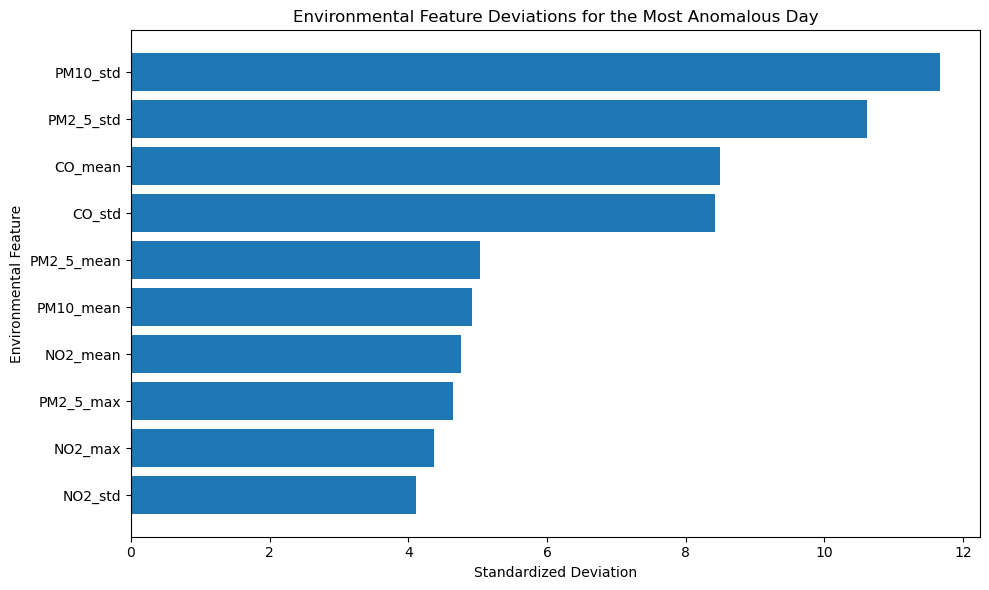

In [109]:
# Select top 10 unusual features

plot_data = (
    deviation_df
    .sort_values(
        "Absolute Deviation",
        ascending=False
    )
    .head(10)
    .sort_values(
        "Standardized Deviation"
    )
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Standardized Deviation"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Standardized Deviation")
plt.ylabel("Environmental Feature")
plt.title(
    "Environmental Feature Deviations for the Most Anomalous Day"
)

plt.tight_layout()
plt.show()

## 10.10 — CREATE AN ANOMALY EXPLANATION TABLE
Finally, let's create a clean table that we can later use in the report/dashboard.

In [110]:
 # Create final anomaly explanation table

anomaly_explanation = (
    deviation_df
    .sort_values(
        "Absolute Deviation",
        ascending=False
    )
    .head(10)
    .reset_index()
    .rename(
        columns={
            "index": "Feature"
        }
    )
)

anomaly_explanation[
    [
        "Feature",
        "Normal Mean",
        "Anomalous Day",
        "Standardized Deviation"
    ]
]

,Feature,Normal Mean,Anomalous Day,Standardized Deviation
0,PM10_std,16.715278,126.516766,11.660814
1,PM2_5_std,11.746449,105.442385,10.61648
2,CO_mean,1109.171863,6790.902778,8.487624
3,CO_std,240.097503,1735.705061,8.422645
4,PM2_5_mean,71.333243,340.161111,5.030917
5,PM10_mean,96.336446,389.756944,4.924057
6,NO2_mean,47.951999,145.996528,4.764905
7,PM2_5_max,179.048650,677.0,4.648514
8,NO2_max,119.402453,276.0,4.368739
9,NO2_std,13.834576,35.60676,4.104986


# STEP 11 — ANOMALY TYPE CLASSIFICATION
## 11.1 — CREATE FEATURE GROUPS
Detected anomalous days will be further categorized based on the environmental features contributing to their unusual behavior.

The features will be divided into pollution-related and weather-related groups to distinguish different types of environmental anomalies.

In [111]:
# Define pollution and weather feature groups

pollution_features = [
    "PM2.5_mean",
    "PM2.5_max",
    "PM2.5_std",
    "PM10_mean",
    "PM10_max",
    "PM10_std",
    "SO2_mean",
    "SO2_max",
    "SO2_std",
    "NO2_mean",
    "NO2_max",
    "NO2_std",
    "CO_mean",
    "CO_max",
    "CO_std",
    "O3_mean",
    "O3_max",
    "O3_std"
]

weather_features = [
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]

print("Pollution features:", len(pollution_features))
print("Weather features:", len(weather_features))

Pollution features: 18
Weather features: 5


## 11.2 STANDARDIZED DEVIATIONS FOR ANOMALOUS DAYS

The standardized deviation of each environmental feature will be calculated for every anomalous day.

The deviations will be compared with the normal-day distribution to determine which environmental feature groups contribute most strongly to each anomaly.

In [112]:
print("Anomaly DataFrame shape:")
print(anomaly_df.shape)

print("\nColumns in anomaly_df:")
print(anomaly_df.columns.tolist())

Anomaly DataFrame shape:
(1461, 28)

Columns in anomaly_df:
['date', 'PM2_5_mean', 'PM2_5_max', 'PM2_5_std', 'PM10_mean', 'PM10_max', 'PM10_std', 'SO2_mean', 'SO2_max', 'SO2_std', 'NO2_mean', 'NO2_max', 'NO2_std', 'CO_mean', 'CO_max', 'CO_std', 'O3_mean', 'O3_max', 'O3_std', 'TEMP_mean', 'PRES_mean', 'DEWP_mean', 'RAIN_sum', 'WSPM_mean', 'cluster', 'anomaly_label', 'anomaly_score', 'year']


In [113]:

print("\nChecking required pollution features:")

for feature in pollution_features:
    print(feature, "->", feature in anomaly_df.columns)

print("\nChecking required weather features:")

for feature in weather_features:
    print(feature, "->", feature in anomaly_df.columns)


Checking required pollution features:
PM2.5_mean -> False
PM2.5_max -> False
PM2.5_std -> False
PM10_mean -> True
PM10_max -> True
PM10_std -> True
SO2_mean -> True
SO2_max -> True
SO2_std -> True
NO2_mean -> True
NO2_max -> True
NO2_std -> True
CO_mean -> True
CO_max -> True
CO_std -> True
O3_mean -> True
O3_max -> True
O3_std -> True

Checking required weather features:
TEMP_mean -> True
PRES_mean -> True
DEWP_mean -> True
RAIN_sum -> True
WSPM_mean -> True


In [114]:
# Calculate standardized deviations for all anomalous days

# Select normal and anomalous days
normal_days_df = anomaly_df[
    anomaly_df["anomaly_label"] == 1
]

anomalous_data = anomaly_df[
    anomaly_df["anomaly_label"] == -1
].copy()


# Use the actual feature names present in anomaly_df
analysis_features = [
    "PM2_5_mean",
    "PM2_5_max",
    "PM2_5_std",
    
    "PM10_mean",
    "PM10_max",
    "PM10_std",
    
    "SO2_mean",
    "SO2_max",
    "SO2_std",
    
    "NO2_mean",
    "NO2_max",
    "NO2_std",
    
    "CO_mean",
    "CO_max",
    "CO_std",
    
    "O3_mean",
    "O3_max",
    "O3_std",
    
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]


# Calculate normal-day statistics
normal_mean = normal_days_df[
    analysis_features
].mean()

normal_std = normal_days_df[
    analysis_features
].std()


# Calculate standardized deviations
anomaly_deviation = (
    anomalous_data[analysis_features] - normal_mean
) / normal_std.replace(0, np.nan)


print("Number of anomalous days:", len(anomalous_data))
print("Number of analysis features:", len(analysis_features))
print("Deviation matrix shape:", anomaly_deviation.shape)

Number of anomalous days: 73
Number of analysis features: 23
Deviation matrix shape: (73, 23)


## 11.3 POLLUTION AND WEATHER ANOMALY SCORES

Separate anomaly scores will be calculated for pollution-related and weather-related features.

The scores represent the average magnitude of standardized deviation from normal conditions.

In [115]:
# Calculate pollution and weather anomaly scores

# Actual feature names present in anomaly_deviation
pollution_columns = [
    "PM2_5_mean",
    "PM2_5_max",
    "PM2_5_std",
    "PM10_mean",
    "PM10_max",
    "PM10_std",
    "SO2_mean",
    "SO2_max",
    "SO2_std",
    "NO2_mean",
    "NO2_max",
    "NO2_std",
    "CO_mean",
    "CO_max",
    "CO_std",
    "O3_mean",
    "O3_max",
    "O3_std"
]

weather_columns = [
    "TEMP_mean",
    "PRES_mean",
    "DEWP_mean",
    "RAIN_sum",
    "WSPM_mean"
]


# Calculate average absolute deviation
pollution_score = (
    anomaly_deviation[pollution_columns]
    .abs()
    .mean(axis=1)
)

weather_score = (
    anomaly_deviation[weather_columns]
    .abs()
    .mean(axis=1)
)


# Create anomaly type score table
anomaly_type_scores = pd.DataFrame({
    "date": anomalous_data["date"].values,
    "anomaly_score": anomalous_data["anomaly_score"].values,
    "pollution_score": pollution_score.values,
    "weather_score": weather_score.values
})


print("Anomaly type scores calculated successfully.")

print("\nShape:")
print(anomaly_type_scores.shape)

print("\nFirst 5 rows:")
display(anomaly_type_scores.head())

Anomaly type scores calculated successfully.

Shape:
(73, 4)

First 5 rows:


,date,anomaly_score,pollution_score,weather_score
0,2013-03-06,-0.016210,2.049054,0.539854
1,2013-03-07,-0.082936,2.804500,0.530137
2,2013-03-08,-0.069672,2.337741,0.429825
3,2013-03-17,-0.016170,1.811463,0.488846
4,2013-04-08,-0.007009,1.210519,1.466784


## 11.4 COUNT STRONGLY DEVIATING FEATURES

The number of pollution and weather features with an absolute standardized deviation of at least 2 will be calculated.

This provides an additional measure of how broadly an anomaly affects each environmental feature group.

In [116]:
# Count strongly deviating pollution features

pollution_feature_count = (
    anomaly_deviation[pollution_columns]
    .abs()
    .ge(2)
    .sum(axis=1)
)


# Count strongly deviating weather features

weather_feature_count = (
    anomaly_deviation[weather_columns]
    .abs()
    .ge(2)
    .sum(axis=1)
)


# Add counts to anomaly score table

anomaly_type_scores["pollution_features"] = (
    pollution_feature_count.values
)

anomaly_type_scores["weather_features"] = (
    weather_feature_count.values
)


print("Strong deviation counts calculated.")

display(
    anomaly_type_scores.head()
)

Strong deviation counts calculated.


,date,anomaly_score,pollution_score,weather_score,pollution_features,weather_features
0,2013-03-06,-0.016210,2.049054,0.539854,8,0
1,2013-03-07,-0.082936,2.804500,0.530137,14,0
2,2013-03-08,-0.069672,2.337741,0.429825,12,0
3,2013-03-17,-0.016170,1.811463,0.488846,7,0
4,2013-04-08,-0.007009,1.210519,1.466784,2,1


## 11.5 CLASSIFY ANOMALY TYPES

Each anomalous day will be categorized according to the relative strength of its pollution-related and weather-related deviations.

The classification is descriptive and does not imply causation.

In [117]:
# Function to classify anomaly type

def classify_anomaly(row):

    pollution = row["pollution_score"]
    weather = row["weather_score"]

    if pollution >= 2 and weather >= 2:
        return "Multi-Factor"

    elif pollution >= 2 and weather < 2:
        return "Pollution-Dominated"

    elif weather >= 2 and pollution < 2:
        return "Weather-Dominated"

    else:
        return "Mixed / Low-Signal"


# Apply classification

anomaly_type_scores["anomaly_type"] = (
    anomaly_type_scores.apply(
        classify_anomaly,
        axis=1
    )
)


print("Anomaly classification completed.")

display(
    anomaly_type_scores.head(10)
)

Anomaly classification completed.


,date,anomaly_score,pollution_score,weather_score,pollution_features,weather_features,anomaly_type
0,2013-03-06,-0.016210,2.049054,0.539854,8,0,Pollution-Dominated
1,2013-03-07,-0.082936,2.804500,0.530137,14,0,Pollution-Dominated
2,2013-03-08,-0.069672,2.337741,0.429825,12,0,Pollution-Dominated
3,2013-03-17,-0.016170,1.811463,0.488846,7,0,Mixed / Low-Signal
4,2013-04-08,-0.007009,1.210519,1.466784,2,1,Mixed / Low-Signal
5,2013-06-28,-0.049573,1.693856,1.266212,7,0,Mixed / Low-Signal
6,2013-08-11,-0.007074,0.821876,1.915405,1,1,Mixed / Low-Signal
7,2013-08-16,-0.021057,1.947958,1.234424,2,0,Mixed / Low-Signal
8,2013-11-23,-0.069709,2.761072,0.552160,13,0,Pollution-Dominated
9,2013-12-07,-0.073843,2.962491,0.681510,12,0,Pollution-Dominated


## 11.6 ANOMALY TYPE DISTRIBUTION

The number of anomalous days in each environmental anomaly category will be calculated.

In [118]:
# Count anomaly types

anomaly_type_distribution = (
    anomaly_type_scores["anomaly_type"]
    .value_counts()
)


print("Anomaly Type Distribution:")
print(anomaly_type_distribution)

Anomaly Type Distribution:
anomaly_type
Pollution-Dominated    55
Mixed / Low-Signal     18
Name: count, dtype: int64


## 11.7 ANOMALY TYPE SUMMARY

The percentage of anomalous days belonging to each anomaly type will be calculated to compare the relative frequency of different environmental anomaly patterns.

In [119]:
# Calculate percentages

anomaly_type_percentage = (
    anomaly_type_scores["anomaly_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# Create summary table

anomaly_type_summary = pd.DataFrame({
    "Number of Days": anomaly_type_distribution,
    "Percentage": anomaly_type_percentage
})


anomaly_type_summary

,Number of Days,Percentage
anomaly_type,,
Pollution-Dominated,55,75.34
Mixed / Low-Signal,18,24.66


## 11.8 STRONGEST ANOMALY CLASSIFICATION

The most anomalous day identified by Isolation Forest will be examined to determine whether its unusual behavior is primarily associated with pollution, weather, or multiple environmental factors.

In [120]:
# Get the strongest anomaly

strongest_anomaly = (
    anomaly_type_scores
    .sort_values(
        "anomaly_score",
        ascending=True
    )
    .iloc[0]
)


print("Strongest anomalous date:")
print(strongest_anomaly["date"])

print("\nIsolation Forest score:")
print(
    round(
        strongest_anomaly["anomaly_score"],
        6
    )
)

print("\nPollution score:")
print(
    round(
        strongest_anomaly["pollution_score"],
        3
    )
)

print("\nWeather score:")
print(
    round(
        strongest_anomaly["weather_score"],
        3
    )
)

print("\nStrongly deviating pollution features:")
print(
    strongest_anomaly["pollution_features"]
)

print("\nStrongly deviating weather features:")
print(
    strongest_anomaly["weather_features"]
)

print("\nAnomaly type:")
print(
    strongest_anomaly["anomaly_type"]
)

Strongest anomalous date:
2017-01-04 00:00:00

Isolation Forest score:
-0.151829

Pollution score:
4.423

Weather score:
0.812

Strongly deviating pollution features:
12

Strongly deviating weather features:
0

Anomaly type:
Pollution-Dominated


## 11.9 ANOMALY TYPE DISTRIBUTION

The distribution of detected anomaly types will be visualized to provide an overview of the different unusual environmental patterns identified by the system.

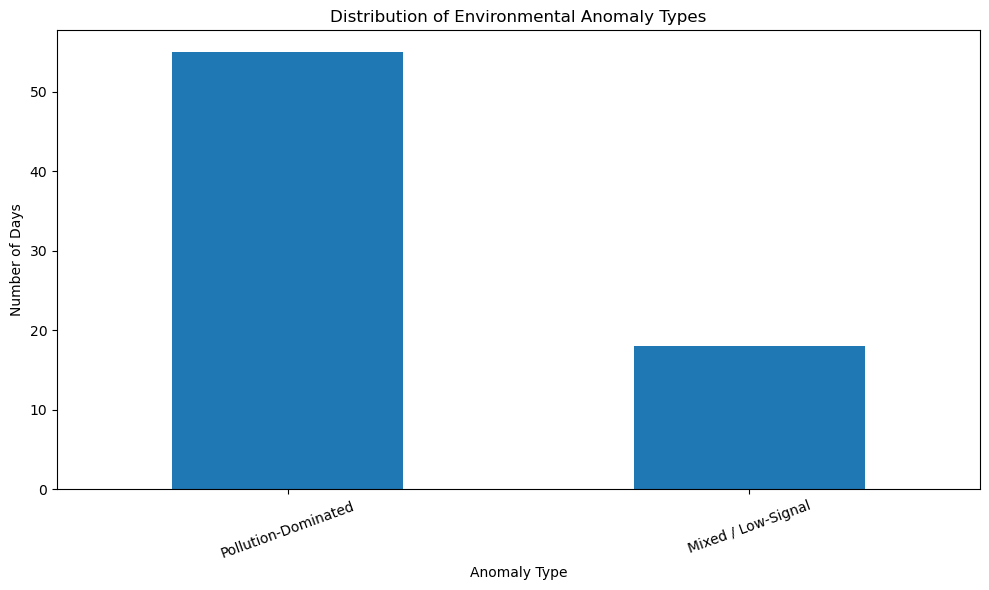

In [121]:
plt.figure(figsize=(10, 6))

anomaly_type_distribution.plot(
    kind="bar"
)

plt.xlabel("Anomaly Type")
plt.ylabel("Number of Days")
plt.title("Distribution of Environmental Anomaly Types")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## 11.10 FINAL ANOMALY REPORT

A consolidated anomaly report will be created containing the anomm
aly score, pollution deviation, weather deviation, and assigned anomaly type for each detected anomalous day.

In [122]:
# Create final anomaly report

final_anomaly_report = (
    anomaly_type_scores[
        [
            "date",
            "anomaly_score",
            "pollution_score",
            "weather_score",
            "pollution_features",
            "weather_features",
            "anomaly_type"
        ]
    ]
    .sort_values(
        "anomaly_score",
        ascending=True
    )
)


print(
    "Final anomaly report shape:",
    final_anomaly_report.shape
)

display(
    final_anomaly_report.head(20)
)

Final anomaly report shape: (73, 7)


,date,anomaly_score,pollution_score,weather_score,pollution_features,weather_features,anomaly_type
68,2017-01-04,-0.151829,4.422821,0.811812,12,0,Pollution-Dominated
14,2014-01-16,-0.141034,3.949526,0.799358,14,0,Pollution-Dominated
51,2015-12-25,-0.135242,3.841774,0.675142,12,0,Pollution-Dominated
71,2017-01-28,-0.126874,2.979291,0.751302,9,0,Pollution-Dominated
23,2014-02-26,-0.123068,3.270869,0.457191,15,0,Pollution-Dominated
67,2017-01-03,-0.123017,3.439080,0.808398,12,0,Pollution-Dominated
10,2013-12-24,-0.122131,3.537273,1.108386,14,0,Pollution-Dominated
46,2015-11-30,-0.120554,3.917909,0.816751,12,0,Pollution-Dominated
17,2014-02-15,-0.107844,3.216251,0.809129,13,0,Pollution-Dominated
61,2016-12-20,-0.107810,3.229321,0.845116,11,0,Pollution-Dominated


## 11.11 SAVE ANOMALY RESULTS

The final anomaly results will be saved as a CSV file for further analysis, reporting, and visualization.

In [123]:
# Save final anomaly report

final_anomaly_report.to_csv(
    "final_anomaly_report.csv",
    index=False
)

print(
    "Final anomaly report saved successfully."
)

Final anomaly report saved successfully.


# STEP 12 — TEMPORAL AND SEASONAL ANOMALY ANALYSIS
## 12.1 ANOMALIES BY YEAR

The number of anomalous days will be analyzed for each year to identify whether environmental anomalies are more frequent during particular years.


In [124]:
# Extract year from date

anomaly_df["year"] = anomaly_df["date"].dt.year


# Select anomalous days

yearly_anomalies = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .groupby("year")
    .size()
)


print("Number of anomalous days by year:")
print(yearly_anomalies)

Number of anomalous days by year:
year
2013    12
2014    25
2015    17
2016    11
2017     8
dtype: int64


## 12.2 TOTAL OBSERVED DAYS BY YEAR

The total number of observed city-days in each year will be calculated so that anomaly frequency can be compared fairly across years.

In [125]:
# Count total city-days for each year

total_days_by_year = (
    anomaly_df
    .groupby("year")
    .size()
)


print("Total observed days by year:")
print(total_days_by_year)

Total observed days by year:
year
2013    306
2014    365
2015    365
2016    366
2017     59
dtype: int64


## 12.3 YEARLY ANOMALY PERCENTAGE

The percentage of anomalous days for each year will be calculated by comparing anomalous days with the total observed days in that year.     

In [126]:
# Calculate yearly anomaly percentage

yearly_anomaly_percentage = (
    yearly_anomalies
    .div(total_days_by_year)
    .mul(100)
    .round(2)
)


yearly_summary = pd.DataFrame({
    "Total Days": total_days_by_year,
    "Anomalous Days": yearly_anomalies,
    "Anomaly Percentage": yearly_anomaly_percentage
}).fillna(0)


yearly_summary

,Total Days,Anomalous Days,Anomaly Percentage
year,,,
2013,306,12,3.92
2014,365,25,6.85
2015,365,17,4.66
2016,366,11,3.01
2017,59,8,13.56


# Calculate yearly anomaly percentage

yearly_anomaly_percentage = (
    yearly_anomalies
    .div(total_days_by_year)
    .mul(100)
    .round(2)
)


yearly_summary = pd.DataFrame({
    "Total Days": total_days_by_year,
    "Anomalous Days": yearly_anomalies,
    "Anomaly Percentage": yearly_anomaly_percentage
}).fillna(0)


yearly_summary

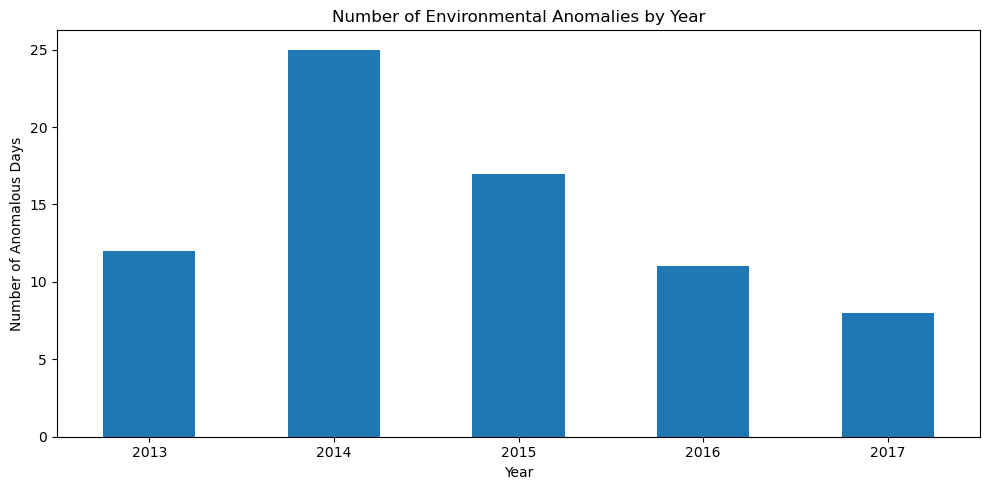

In [127]:
plt.figure(figsize=(10, 5))

yearly_anomalies.plot(
    kind="bar"
)

plt.xlabel("Year")
plt.ylabel("Number of Anomalous Days")
plt.title("Number of Environmental Anomalies by Year")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 12.5 MONTHLY ANOMALY ANALYSIS

The distribution of anomalous days across months will be analyzed to identify recurring seasonal patterns in environmental anomalies.

In [128]:
# Extract month from date

anomaly_df["month"] = anomaly_df["date"].dt.month


# Count anomalous days by month

monthly_anomalies = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .groupby("month")
    .size()
)


print("Number of anomalous days by month:")
print(monthly_anomalies)

Number of anomalous days by month:
month
1     15
2     12
3      7
4      1
5      3
6      2
8      2
10     5
11     6
12    20
dtype: int64


## 12.6 TOTAL OBSERVED DAYS BY MONTH

The total number of observed days for each month will be calculated to support fair comparison of anomaly frequency across months.

In [129]:
# Count total observed days by month

total_days_by_month = (
    anomaly_df
    .groupby("month")
    .size()
)


print("Total observed days by month:")
print(total_days_by_month)

Total observed days by month:
month
1     124
2     113
3     124
4     120
5     124
6     120
7     124
8     124
9     120
10    124
11    120
12    124
dtype: int64


## 12.7 MONTHLY ANOMALY PERCENTAGE

The percentage of anomalous days for each month will be calculated to identify months with relatively higher anomaly occurrence.

In [130]:
# Calculate monthly anomaly percentage

monthly_anomaly_percentage = (
    monthly_anomalies
    .div(total_days_by_month)
    .mul(100)
    .round(2)
)


monthly_summary = pd.DataFrame({
    "Total Days": total_days_by_month,
    "Anomalous Days": monthly_anomalies,
    "Anomaly Percentage": monthly_anomaly_percentage
}).fillna(0)


monthly_summary

,Total Days,Anomalous Days,Anomaly Percentage
month,,,
1,124,15.0,12.10
2,113,12.0,10.62
3,124,7.0,5.65
4,120,1.0,0.83
5,124,3.0,2.42
6,120,2.0,1.67
7,124,0.0,0.00
8,124,2.0,1.61
9,120,0.0,0.00


## 12.8 MONTHLY ANOMALY DISTRIBUTION

The monthly anomaly percentages will be visualized to identify months with relatively higher environmental anomaly frequency.

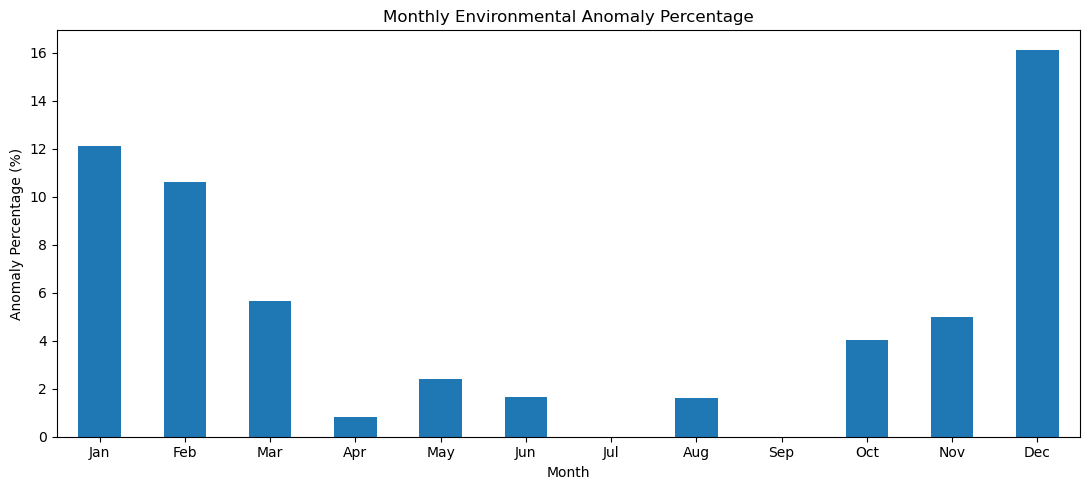

In [131]:
plt.figure(figsize=(11, 5))

monthly_anomaly_percentage.plot(
    kind="bar"
)

plt.xlabel("Month")
plt.ylabel("Anomaly Percentage (%)")
plt.title("Monthly Environmental Anomaly Percentage")

plt.xticks(
    range(12),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=0
)

plt.tight_layout()
plt.show()

## 12.9 SEASONAL ANOMALY ANALYSIS

The months will be grouped into four seasons to analyze whether environmental anomalies show a seasonal pattern.

In [132]:
# Define seasons

season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    
    3: "Spring",
    4: "Spring",
    5: "Spring",
    
    6: "Summer",
    7: "Summer",
    8: "Summer",
    
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}


# Create season column

anomaly_df["season"] = (
    anomaly_df["month"].map(season_map)
)


# Count total days by season

total_days_by_season = (
    anomaly_df
    .groupby("season")
    .size()
)


# Count anomalous days by season

seasonal_anomalies = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]
    .groupby("season")
    .size()
)


# Calculate anomaly percentage

seasonal_anomaly_percentage = (
    seasonal_anomalies
    .div(total_days_by_season)
    .mul(100)
    .round(2)
)


# Create summary table

seasonal_summary = pd.DataFrame({
    "Total Days": total_days_by_season,
    "Anomalous Days": seasonal_anomalies,
    "Anomaly Percentage": seasonal_anomaly_percentage
}).fillna(0)


seasonal_summary

,Total Days,Anomalous Days,Anomaly Percentage
season,,,
Autumn,364,11,3.02
Spring,368,11,2.99
Summer,368,4,1.09
Winter,361,47,13.02


## 12.10 SEASONAL ANOMALY DISTRIBUTION

The anomaly percentage for each season will be visualized to compare the frequency of environmental anomalies across seasons.

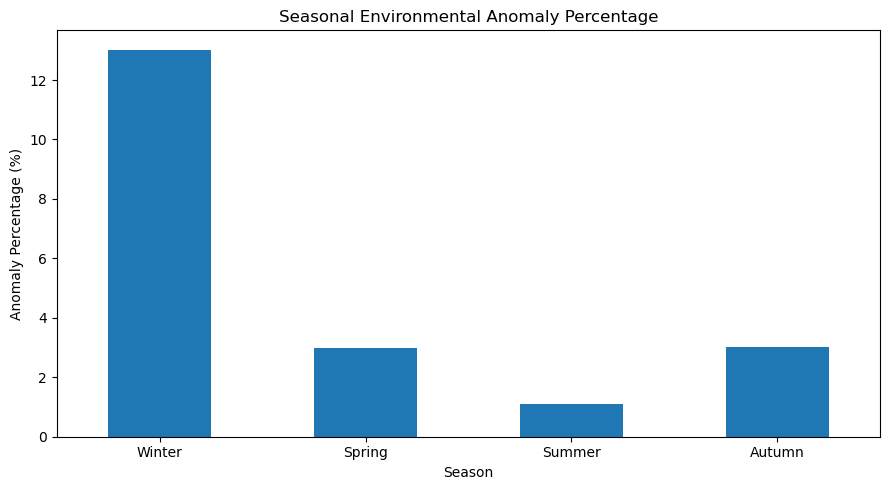

In [133]:
# Plot seasonal anomaly percentage

plt.figure(figsize=(9, 5))

seasonal_anomaly_percentage.reindex(
    ["Winter", "Spring", "Summer", "Autumn"]
).plot(
    kind="bar"
)

plt.xlabel("Season")
plt.ylabel("Anomaly Percentage (%)")
plt.title("Seasonal Environmental Anomaly Percentage")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 12.11 SEASONAL ANOMALY COUNT

The number of anomalous days in each season will be visualized to show the contribution of each season to the total detected anomalies.

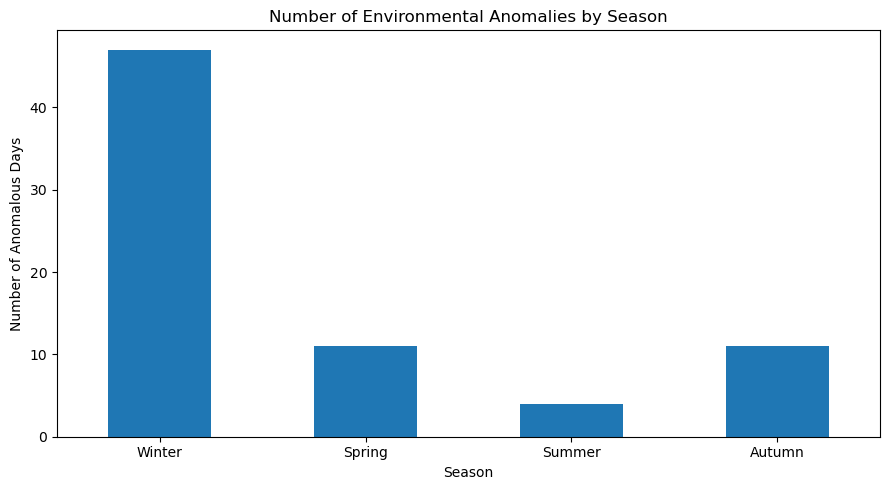

In [134]:
# Plot number of anomalous days by season

plt.figure(figsize=(9, 5))

seasonal_anomalies.reindex(
    ["Winter", "Spring", "Summer", "Autumn"]
).plot(
    kind="bar"
)

plt.xlabel("Season")
plt.ylabel("Number of Anomalous Days")
plt.title("Number of Environmental Anomalies by Season")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 12.12 ANOMALY TYPE BY SEASON

The relationship between season and anomaly type will be analyzed to determine whether pollution-dominated and mixed anomalies occur differently across seasons.

In [135]:
# Add season information to anomaly type results

anomaly_type_scores["season"] = (
    anomaly_type_scores["date"]
    .dt.month
    .map(season_map)
)


# Create season vs anomaly type table

season_type_table = pd.crosstab(
    anomaly_type_scores["season"],
    anomaly_type_scores["anomaly_type"]
)


# Reorder seasons

season_type_table = season_type_table.reindex(
    ["Winter", "Spring", "Summer", "Autumn"]
).fillna(0)


print("Anomaly Type by Season:")
display(season_type_table)

Anomaly Type by Season:


anomaly_type,Mixed / Low-Signal,Pollution-Dominated
season,,
Winter,4,43
Spring,6,5
Summer,4,0
Autumn,4,7


## 12.13 ANOMALY TYPE PERCENTAGE BY SEASON

The percentage distribution of anomaly types within each season will be calculated to compare the composition of environmental anomalies across seasons.

In [136]:
# Calculate percentage of anomaly types within each season

season_type_percentage = (
    season_type_table
    .div(
        season_type_table.sum(axis=1),
        axis=0
    )
    .mul(100)
    .round(2)
)


print("Anomaly Type Percentage by Season:")

display(
    season_type_percentage
)

Anomaly Type Percentage by Season:


anomaly_type,Mixed / Low-Signal,Pollution-Dominated
season,,
Winter,8.51,91.49
Spring,54.55,45.45
Summer,100.00,0.00
Autumn,36.36,63.64


## 12.14 SEASONAL ANOMALY TYPE COMPARISON

The composition of anomaly types across seasons will be visualized using a stacked bar chart.

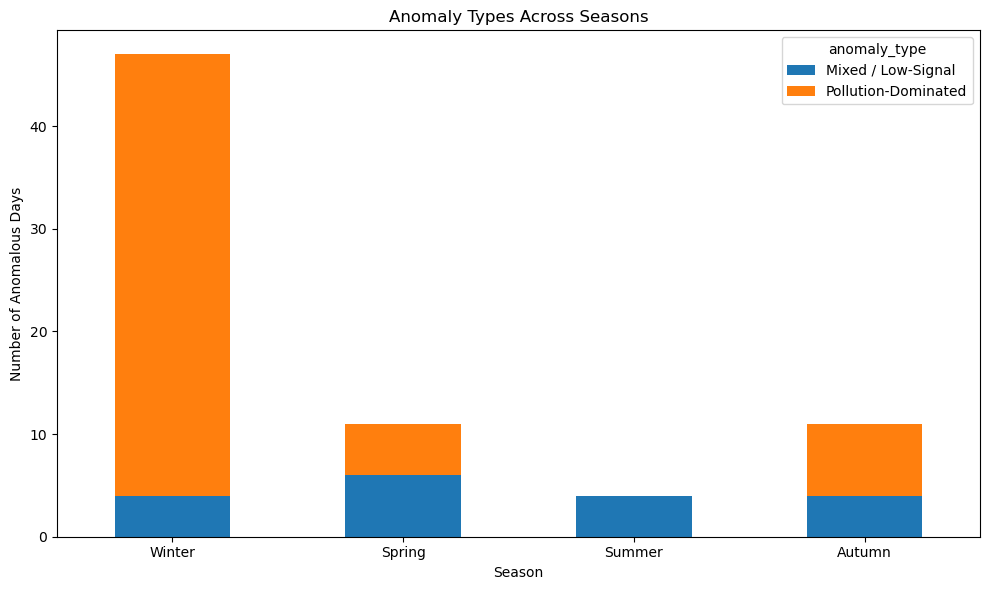

In [137]:
# Plot anomaly types by season

season_type_table.reindex(
    ["Winter", "Spring", "Summer", "Autumn"]
).plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Season")
plt.ylabel("Number of Anomalous Days")
plt.title("Anomaly Types Across Seasons")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# STEP 13 — STATION-LEVEL ANOMALY ANALYSIS
## 13.1 PREPARE STATION-LEVEL DAILY DATA

The station-level daily dataset will be prepared for analyzing whether city-wide anomalous days are localized to individual monitoring stations or observed across multiple stations.

In [138]:
# Create a separate copy of station-level daily data

station_daily_df = daily_df.copy()


# Rename PM2.5 columns to match the anomaly analysis naming convention

station_daily_df = station_daily_df.rename(
    columns={
        "PM2.5_mean": "PM2_5_mean",
        "PM2.5_max": "PM2_5_max"
    }
)


print("Station-level daily dataset shape:")
print(station_daily_df.shape)


print("\nNumber of monitoring stations:")
print(station_daily_df["station"].nunique())


print("\nStations:")
print(station_daily_df["station"].unique())

Station-level daily dataset shape:
(17532, 19)

Number of monitoring stations:
12

Stations:
['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']


## 13.2 IDENTIFY CITY-LEVEL ANOMALOUS DATES

The dates classified as anomalous by the city-level Isolation Forest model will be extracted for station-level analysis.

In [139]:
# Extract city-level anomalous dates

city_anomaly_dates = (
    anomaly_df[
        anomaly_df["anomaly_label"] == -1
    ]["date"]
    .dt.normalize()
    .unique()
)


print("Number of city-level anomalous dates:")
print(len(city_anomaly_dates))

Number of city-level anomalous dates:
73


## 13.3 MATCH ANOMALOUS DAYS WITH MONITORING STATIONS

The station-level observations corresponding to city-level anomalous dates will be extracted to determine how each monitoring station behaved during anomalous city-days.

In [140]:
# Make sure station-level date is in datetime format

station_daily_df["date"] = pd.to_datetime(
    station_daily_df["date"]
)


# Extract station records corresponding to city-level anomalies

station_anomaly_df = station_daily_df[
    station_daily_df["date"].isin(city_anomaly_dates)
].copy()


print("Station-level records during anomalous city-days:")
print(station_anomaly_df.shape)


print("\nNumber of stations represented:")
print(station_anomaly_df["station"].nunique())

Station-level records during anomalous city-days:
(876, 19)

Number of stations represented:
12


## 13.4 STATION COVERAGE DURING ANOMALOUS DAYS

The number of monitoring stations contributing observations on each anomalous day will be calculated to verify whether the detected anomalies are based on complete station coverage.

In [141]:
# Count stations available for each anomalous date

stations_per_anomaly_day = (
    station_anomaly_df
    .groupby("date")["station"]
    .nunique()
)


print("Minimum stations on an anomalous day:")
print(stations_per_anomaly_day.min())


print("\nMaximum stations on an anomalous day:")
print(stations_per_anomaly_day.max())


print("\nAverage stations on an anomalous day:")
print(round(stations_per_anomaly_day.mean(), 2))

Minimum stations on an anomalous day:
12

Maximum stations on an anomalous day:
12

Average stations on an anomalous day:
12.0


## 13.5 STATION-LEVEL ANOMALY FREQUENCY

The number of city-level anomalous days observed at each monitoring station will be calculated to identify stations that frequently experience unusual environmental conditions.

In [142]:
# Count anomalous dates for each station

station_anomaly_frequency = (
    station_anomaly_df
    .groupby("station")["date"]
    .nunique()
    .sort_values(ascending=False)
)


print("Anomalous days represented at each station:")
print(station_anomaly_frequency)

Anomalous days represented at each station:
station
Aotizhongxin     73
Changping        73
Dingling         73
Dongsi           73
Guanyuan         73
Gucheng          73
Huairou          73
Nongzhanguan     73
Shunyi           73
Tiantan          73
Wanliu           73
Wanshouxigong    73
Name: date, dtype: int64


## 13.6 STATION-LEVEL PM2.5 DURING ANOMALOUS DAYS

The average PM2.5 concentration recorded by each monitoring station during city-level anomalous days will be compared to identify stations experiencing relatively higher pollution levels.

In [143]:
# Calculate average PM2.5 during anomalous city-days

station_pm25_anomaly = (
    station_anomaly_df
    .groupby("station")["PM2_5_mean"]
    .mean()
    .sort_values(ascending=False)
)


print("Average PM2.5 during city-level anomalous days:")
print(station_pm25_anomaly)

Average PM2.5 during city-level anomalous days:
station
Wanshouxigong    276.285674
Nongzhanguan     268.968730
Dongsi           264.083305
Tiantan          257.958904
Guanyuan         253.947489
Wanliu           252.821918
Gucheng          249.790525
Aotizhongxin     245.229054
Shunyi           239.411815
Changping        201.761204
Huairou          194.373591
Dingling         194.319127
Name: PM2_5_mean, dtype: float64


## 13.7 STATION-LEVEL DEVIATION FROM NORMAL

For each monitoring station, the average PM2.5 concentration during normal days will be compared with its average PM2.5 concentration during city-level anomalous days.

This helps identify whether an anomalous city-day is associated with unusually high pollution at specific monitoring stations.


In [144]:
# Identify normal city-level dates

city_normal_dates = (
    anomaly_df[
        anomaly_df["anomaly_label"] == 1
    ]["date"]
    .dt.normalize()
    .unique()
)


# Extract station-level observations for normal city-days

station_normal_df = station_daily_df[
    station_daily_df["date"].isin(city_normal_dates)
].copy()


# Calculate average PM2.5 during normal city-days

normal_pm25_by_station = (
    station_normal_df
    .groupby("station")["PM2_5_mean"]
    .mean()
)


# Calculate average PM2.5 during anomalous city-days

anomaly_pm25_by_station = (
    station_anomaly_df
    .groupby("station")["PM2_5_mean"]
    .mean()
)


# Create comparison table

station_pm25_comparison = pd.DataFrame({
    "Normal Mean PM2.5": normal_pm25_by_station,
    "Anomalous Mean PM2.5": anomaly_pm25_by_station
})


# Calculate difference

station_pm25_comparison["Difference"] = (
    station_pm25_comparison["Anomalous Mean PM2.5"]
    - station_pm25_comparison["Normal Mean PM2.5"]
)


# Calculate percentage increase

station_pm25_comparison["Percentage Increase"] = (
    station_pm25_comparison["Difference"]
    / station_pm25_comparison["Normal Mean PM2.5"]
    * 100
)


# Sort by percentage increase

station_pm25_comparison = (
    station_pm25_comparison
    .sort_values(
        "Percentage Increase",
        ascending=False
    )
)


display(station_pm25_comparison.round(2))

,Normal Mean PM2.5,Anomalous Mean PM2.5,Difference,Percentage Increase
station,,,,
Wanshouxigong,75.01,276.29,201.27,268.33
Nongzhanguan,75.41,268.97,193.56,256.68
Tiantan,72.78,257.96,185.18,254.43
Dongsi,76.79,264.08,187.30,243.92
Guanyuan,73.90,253.95,180.05,243.63
Wanliu,74.56,252.82,178.26,239.08
Shunyi,71.02,239.41,168.39,237.08
Gucheng,75.36,249.79,174.43,231.47
Aotizhongxin,73.98,245.23,171.24,231.46


## 13.8 MOST AFFECTED MONITORING STATION

The monitoring station with the largest relative increase in PM2.5 during city-level anomalous days will be identified.

In [145]:
# Identify station with highest relative PM2.5 increase

most_affected_station = (
    station_pm25_comparison
    .sort_values(
        "Percentage Increase",
        ascending=False
    )
    .iloc[0]
)


print("Most affected station:")
print(station_pm25_comparison.index[0])


print("\nNormal PM2.5:")
print(
    round(
        most_affected_station["Normal Mean PM2.5"],
        2
    )
)


print("\nAnomalous-day PM2.5:")
print(
    round(
        most_affected_station["Anomalous Mean PM2.5"],
        2
    )
)


print("\nPercentage increase:")
print(
    round(
        most_affected_station["Percentage Increase"],
        2
    ),
    "%"
)

Most affected station:
Wanshouxigong

Normal PM2.5:
75.01

Anomalous-day PM2.5:
276.29

Percentage increase:
268.33 %


## 13.9 STATION-LEVEL PM2.5 COMPARISON

Average PM2.5 concentrations during normal and anomalous city-days will be compared across monitoring stations.

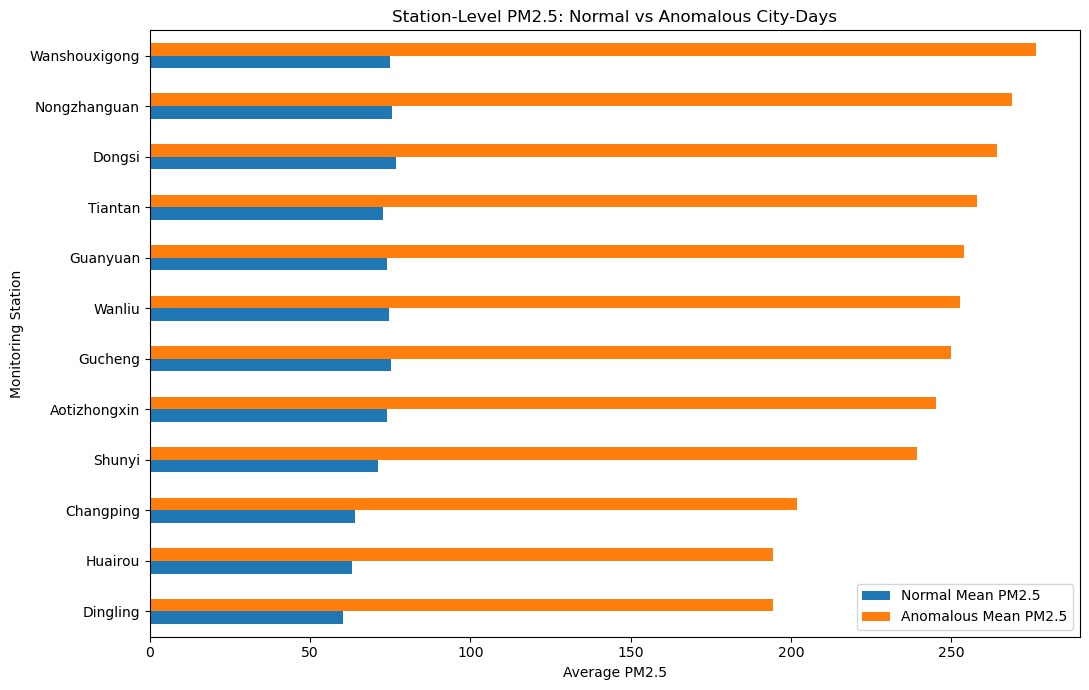

In [146]:
    # Plot normal vs anomalous PM2.5

station_pm25_plot = station_pm25_comparison[
    [
        "Normal Mean PM2.5",
        "Anomalous Mean PM2.5"
    ]
].sort_values(
    "Anomalous Mean PM2.5",
    ascending=True
)


station_pm25_plot.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.xlabel("Average PM2.5")
plt.ylabel("Monitoring Station")
plt.title(
    "Station-Level PM2.5: Normal vs Anomalous City-Days"
)

plt.tight_layout()
plt.show()

## 13.10 CITY-WIDE VS LOCALIZED POLLUTION CHANGE

The number of monitoring stations showing increased average PM2.5 during anomalous city-days will be calculated to determine whether the pollution anomaly is broadly distributed or concentrated at a small number of stations.

In [147]:
# Check whether PM2.5 increased at each station

station_pm25_comparison["PM2.5 Increased"] = (
    station_pm25_comparison["Difference"] > 0
)


increased_count = (
    station_pm25_comparison["PM2.5 Increased"]
    .sum()
)


total_stations = len(
    station_pm25_comparison
)


increased_percentage = (
    increased_count
    / total_stations
    * 100
)


print(
    "Stations with increased PM2.5:",
    increased_count
)


print(
    "Total stations:",
    total_stations
)


print(
    "Percentage of stations with increased PM2.5:",
    round(increased_percentage, 2),
    "%"
)

Stations with increased PM2.5: 12
Total stations: 12
Percentage of stations with increased PM2.5: 100.0 %


## 13.11 STATION-LEVEL POLLUTION INCREASE RANKING

Monitoring stations will be ranked according to the percentage increase in average PM2.5 concentration during anomalous city-days compared with normal city-days.

In [148]:
# Rank stations by PM2.5 percentage increase

station_ranking = (
    station_pm25_comparison[
        [
            "Normal Mean PM2.5",
            "Anomalous Mean PM2.5",
            "Difference",
            "Percentage Increase"
        ]
    ]
    .sort_values(
        "Percentage Increase",
        ascending=False
    )
)


display(
    station_ranking.round(2)
)

,Normal Mean PM2.5,Anomalous Mean PM2.5,Difference,Percentage Increase
station,,,,
Wanshouxigong,75.01,276.29,201.27,268.33
Nongzhanguan,75.41,268.97,193.56,256.68
Tiantan,72.78,257.96,185.18,254.43
Dongsi,76.79,264.08,187.30,243.92
Guanyuan,73.90,253.95,180.05,243.63
Wanliu,74.56,252.82,178.26,239.08
Shunyi,71.02,239.41,168.39,237.08
Gucheng,75.36,249.79,174.43,231.47
Aotizhongxin,73.98,245.23,171.24,231.46


## 13.12 STATION-LEVEL POLLUTION INCREASE VISUALIZATION

The percentage increase in PM2.5 across monitoring stations will be visualized to compare the severity of pollution changes during anomalous city-days.

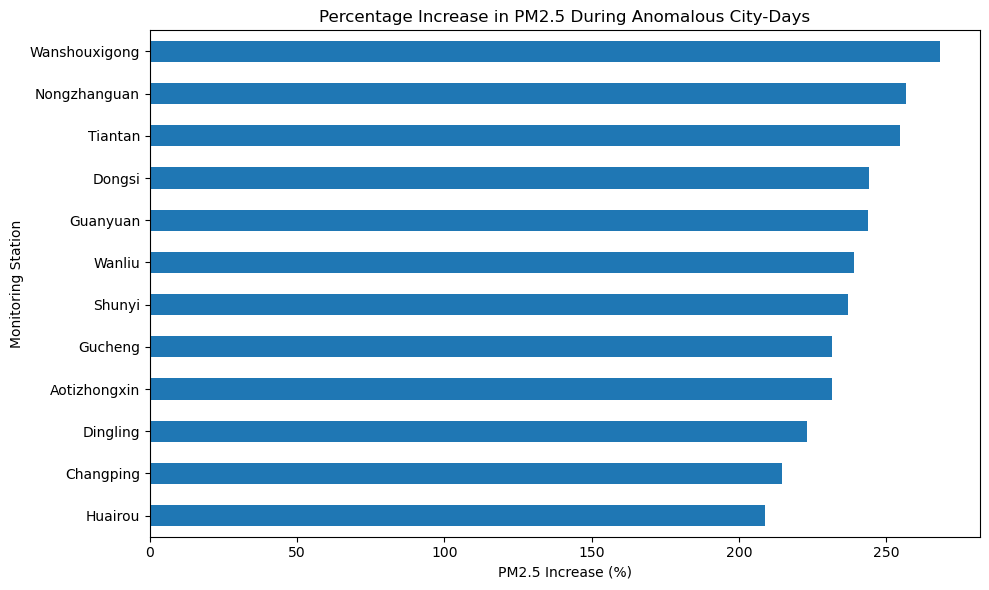

In [149]:
# Plot percentage increase in PM2.5

station_ranking["Percentage Increase"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("PM2.5 Increase (%)")
plt.ylabel("Monitoring Station")
plt.title(
    "Percentage Increase in PM2.5 During Anomalous City-Days"
)

plt.tight_layout()
plt.show()

# STEP 14 — FINAL MODEL INTERPRETATION
## 14.1 OVERALL PROJECT STATISTICS

The main statistics obtained from data preprocessing, clustering, and anomaly detection are summarized to provide an overall view of the environmental analysis.

In [150]:
    # Overall project statistics

total_city_days = len(anomaly_df)

total_anomalous_days = (
    anomaly_df["anomaly_label"] == -1
).sum()

total_normal_days = (
    anomaly_df["anomaly_label"] == 1
).sum()

anomaly_percentage = (
    total_anomalous_days
    / total_city_days
    * 100
)

print("TOTAL CITY-DAYS:", total_city_days)
print("NORMAL DAYS:", total_normal_days)
print("ANOMALOUS DAYS:", total_anomalous_days)
print(
    "ANOMALY PERCENTAGE:",
    round(anomaly_percentage, 2),
    "%"
)

print("\nNUMBER OF MONITORING STATIONS:")
print(master_df["station"].nunique())

print("\nNUMBER OF DAILY FEATURES USED:")
print(len(ml_features))

TOTAL CITY-DAYS: 1461
NORMAL DAYS: 1388
ANOMALOUS DAYS: 73
ANOMALY PERCENTAGE: 5.0 %

NUMBER OF MONITORING STATIONS:
12

NUMBER OF DAILY FEATURES USED:
23


## 14.2 K-MEANS FINAL INTERPRETATION

K-Means clustering was evaluated for different numbers of clusters using inertia and silhouette score. K = 2 produced the highest silhouette score and was therefore selected as the final clustering configuration.

The two clusters represent different environmental condition profiles in the city-level daily dataset.

In [151]:
# Final K-Means cluster summary

print("Selected K:", 2)

print("\nCluster distribution:")
display(cluster_summary)

print("\nCluster profiles:")
display(cluster_profile.round(2))

Selected K: 2

Cluster distribution:


,Number of Days,Percentage
cluster,,
0,357,24.44
1,1104,75.56



Cluster profiles:


,PM2_5_mean,PM2_5_max,PM2_5_std,PM10_mean,PM10_max,PM10_std,SO2_mean,SO2_max,SO2_std,NO2_mean,...,CO_max,CO_std,O3_mean,O3_max,O3_std,TEMP_mean,PRES_mean,DEWP_mean,RAIN_sum,WSPM_mean
cluster,,,,,,,,,,,,,,,,,,,,,
0,157.73,340.33,25.68,186.86,432.17,30.72,36.02,105.12,9.51,82.68,...,5633.01,507.71,26.82,97.69,9.20,5.41,1015.94,-3.67,2.50,1.32
1,54.65,147.62,9.35,78.41,244.68,14.33,9.41,39.88,3.08,40.22,...,2344.52,190.63,67.07,165.37,12.02,16.16,1009.08,4.47,23.75,1.86


## 14.3 ISOLATION FOREST FINAL INTERPRETATION

Isolation Forest was used to identify daily environmental conditions that significantly differed from normal historical patterns. The model classified approximately 5% of the city-level daily observations as anomalous.

In [152]:
# Final Isolation Forest summary

print("Isolation Forest contamination:", 0.05)

print("\nTotal observations:", total_city_days)
print("Normal observations:", normal_count)
print("Anomalous observations:", anomaly_count)

print(
    "\nAnomaly percentage:",
    round(anomaly_percentage, 2),
    "%"
)

Isolation Forest contamination: 0.05

Total observations: 1461
Normal observations: 1388
Anomalous observations: 73

Anomaly percentage: 5.0 %


## 14.4 MOST ANOMALOUS ENVIRONMENTAL DAY

The day with the lowest Isolation Forest decision score is considered the most anomalous environmental day in the dataset.

In [153]:
# Most anomalous day

most_anomalous_day = (
    anomaly_df
    .sort_values("anomaly_score", ascending=True)
    .iloc[0]
)

print("Most anomalous date:")
print(most_anomalous_day["date"])

print("\nIsolation Forest score:")
print(round(most_anomalous_day["anomaly_score"], 6))

print("\nCluster:")
print(most_anomalous_day["cluster"])

Most anomalous date:
2017-01-04 00:00:00

Isolation Forest score:
-0.151829

Cluster:
0


## 14.5 MOST IMPORTANT ENVIRONMENTAL FEATURES

The environmental features showing the largest standardized deviations on the most anomalous day are identified to improve the interpretability of the anomaly detection model.

In [154]:
# Top features contributing to the most anomalous day

final_feature_contribution = (
    top_unusual_features[
        [
            "Normal Mean",
            "Normal Std",
            "Anomalous Day",
            "Standardized Deviation"
        ]
    ]
    .head(10)
)

display(
    final_feature_contribution.round(2)
)

,Normal Mean,Normal Std,Anomalous Day,Standardized Deviation
PM10_std,16.72,9.42,126.516766,11.660814
PM2_5_std,11.75,8.83,105.442385,10.61648
CO_mean,1109.17,669.41,6790.902778,8.487624
CO_std,240.10,177.57,1735.705061,8.422645
PM2_5_mean,71.33,53.44,340.161111,5.030917
PM10_mean,96.34,59.59,389.756944,4.924057
NO2_mean,47.95,20.58,145.996528,4.764905
PM2_5_max,179.05,107.12,677.0,4.648514
NO2_max,119.40,35.85,276.0,4.368739
NO2_std,13.83,5.30,35.60676,4.104986


## 14.6 TEMPORAL AND SEASONAL FINDINGS

The distribution of anomalies across years, months, and seasons is analyzed to identify temporal patterns in unusual environmental conditions.

In [155]:
print("YEARLY ANOMALY SUMMARY")
display(yearly_summary)

print("\nMONTHLY ANOMALY SUMMARY")
display(monthly_summary)

print("\nSEASONAL ANOMALY SUMMARY")
display(seasonal_summary)

YEARLY ANOMALY SUMMARY


,Total Days,Anomalous Days,Anomaly Percentage
year,,,
2013,306,12,3.92
2014,365,25,6.85
2015,365,17,4.66
2016,366,11,3.01
2017,59,8,13.56



MONTHLY ANOMALY SUMMARY


,Total Days,Anomalous Days,Anomaly Percentage
month,,,
1,124,15.0,12.10
2,113,12.0,10.62
3,124,7.0,5.65
4,120,1.0,0.83
5,124,3.0,2.42
6,120,2.0,1.67
7,124,0.0,0.00
8,124,2.0,1.61
9,120,0.0,0.00



SEASONAL ANOMALY SUMMARY


,Total Days,Anomalous Days,Anomaly Percentage
season,,,
Autumn,364,11,3.02
Spring,368,11,2.99
Summer,368,4,1.09
Winter,361,47,13.02


## 14.7 STATION-LEVEL FINDINGS

Station-level analysis is used to determine whether environmental anomalies are localized to individual monitoring stations or occur across the wider monitoring network.

In [156]:
# Final station-level summary

print("Stations showing increased PM2.5:")
print(increased_count)

print("\nTotal monitoring stations:")
print(total_stations)

print(
    "\nPercentage of stations showing increased PM2.5:",
    round(increased_percentage, 2),
    "%"
)

print(
    "\nMost affected station:",
    station_pm25_comparison.index[0]
)

print(
    "PM2.5 percentage increase:",
    round(
        station_pm25_comparison.iloc[0]["Percentage Increase"],
        2
    ),
    "%"
)

Stations showing increased PM2.5:
12

Total monitoring stations:
12

Percentage of stations showing increased PM2.5: 100.0 %

Most affected station: Wanshouxigong
PM2.5 percentage increase: 268.33 %


## 14.8 FINAL KEY FINDINGS

In [157]:
final_findings = pd.DataFrame({
    "Analysis": [
        "Dataset",
        "Monitoring Stations",
        "City-Days",
        "ML Features",
        "Selected K",
        "Anomalous Days",
        "Anomaly Percentage",
        "Most Anomalous Date",
        "Highest Anomaly Season",
        "Highest Anomaly Month",
        "Most Affected Station",
        "Stations with Increased PM2.5"
    ],
    
    "Result": [
        "Beijing Multi-Site Air Quality",
        "12",
        "1461",
        "23",
        "2",
        "73",
        "5.00%",
        "2017-01-04",
        "Winter",
        "December",
        "Wanshouxigong",
        "12 / 12 (100%)"
    ]
})

display(final_findings)

,Analysis,Result
0,Dataset,Beijing Multi-Site Air Quality
1,Monitoring Stations,12
2,City-Days,1461
3,ML Features,23
4,Selected K,2
5,Anomalous Days,73
6,Anomaly Percentage,5.00%
7,Most Anomalous Date,2017-01-04
8,Highest Anomaly Season,Winter
9,Highest Anomaly Month,December


## 14.9 FINAL PROJECT CONCLUSION

The project successfully developed an unsupervised machine learning framework for identifying unusual environmental conditions using the Beijing Multi-Site Air Quality Dataset.

The analysis transformed hourly observations from 12 monitoring stations into daily environmental profiles and applied PCA, K-Means clustering, and Isolation Forest for environmental pattern discovery and anomaly detection.

K-Means identified two major environmental condition groups, while Isolation Forest detected 73 anomalous city-days out of 1461 days. The anomalies were further analyzed across time, seasons, environmental features, and monitoring stations.

The analysis showed that winter and December experienced higher anomaly rates. Station-level analysis showed increased PM2.5 at all 12 monitoring stations during anomalous city-days, indicating that the detected pollution anomalies were predominantly city-wide rather than localized.

The most anomalous day was identified as 4 January 2017, with pollution-related variables showing particularly strong deviations from normal conditions.

In [158]:
from pathlib import Path
import joblib
import os

model_dir = Path(
    r"C:\Users\hukup\Desktop\City Anomaly Project\models"
)

model_dir.mkdir(parents=True, exist_ok=True)

models_to_save = {
    "scaler.pkl": scaler,
    "isolation_forest.pkl": isolation_forest,
    "pca.pkl": pca_13,
    "kmeans_model.pkl": kmeans_final
}

for filename, model in models_to_save.items():
    file_path = model_dir / filename
    joblib.dump(model, file_path)

    print(
        f"{filename}: "
        f"{os.path.getsize(file_path):,} bytes"
    )

print("\nModel export completed.")

scaler.pkl: 1,647 bytes
isolation_forest.pkl: 2,034,169 bytes
pca.pkl: 3,839 bytes
kmeans_model.pkl: 6,779 bytes

Model export completed.
